# Practical Report 6 (PR 6) — Opening the Transformer: Attention, Encoder, Decoder and Inference with Pretrained Models

In [1]:
import torch
import numpy as np
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

torch.manual_seed(42)
np.random.seed(42)

print("Environment ready!")
print("PyTorch:", torch.__version__)

c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\PR 6\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment ready!
PyTorch: 2.14.1+cpu


## Task 1: Introduction, History, Pipelines & Tokenizer


In [2]:

from transformers import pipeline

print("Hugging Face pipeline imported successfully!")



Hugging Face pipeline imported successfully!


In [3]:

clf = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

print("Sentiment model loaded successfully!")


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1137.53it/s]


Sentiment model loaded successfully!


In [4]:

sentences = [
    "I absolutely love this movie!",
    "The food was terrible and disappointing.",
    "The acting was excellent and the story was amazing.",
    "I did not enjoy this film at all.",
    "The movie was not bad, but it was not great either."
]

results = clf(sentences)

for sentence, result in zip(sentences, results):
    print("Sentence:", sentence)
    print("Label:", result["label"])
    print("Score:", round(result["score"], 4))
    print("-" * 60)


Sentence: I absolutely love this movie!
Label: POSITIVE
Score: 0.9999
------------------------------------------------------------
Sentence: The food was terrible and disappointing.
Label: NEGATIVE
Score: 0.9997
------------------------------------------------------------
Sentence: The acting was excellent and the story was amazing.
Label: POSITIVE
Score: 0.9999
------------------------------------------------------------
Sentence: I did not enjoy this film at all.
Label: NEGATIVE
Score: 0.9981
------------------------------------------------------------
Sentence: The movie was not bad, but it was not great either.
Label: NEGATIVE
Score: 0.9982
------------------------------------------------------------



## Task 1.2: Introduction and History of Transformers

**Objective:** Understand the evolution of attention mechanisms and Transformers, and learn why Transformers became an important alternative to RNNs and LSTMs.

**Expected Output:** A timeline table covering 2014–2015, 2017, 2018, 2019, and 2020 onwards, followed by an explanation of the limitations of RNNs and LSTMs.

### Transformer History Timeline

| Year | Model / Paper | Why It Mattered |
|---|---|---|
| 2014–2015 | Sequence-to-Sequence with Attention — Bahdanau / Luong | Attention helped the decoder focus on relevant parts of the input sequence instead of relying only on a single fixed-size representation. |
| 2017 | Attention Is All You Need — Vaswani et al. | Introduced the Transformer architecture based on attention, without requiring recurrent layers. |
| 2018 | BERT and GPT | BERT demonstrated bidirectional contextual representations, while GPT used a decoder-based approach for language modelling and text generation. |
| 2019 | GPT-2, T5 and DistilBERT | GPT-2 advanced text generation, T5 framed many NLP tasks as text-to-text, and DistilBERT offered a smaller, faster model through distillation. |
| 2020 onwards | Large Language Models and Vision Transformers | Transformers expanded into large-scale language applications and image understanding using Vision Transformers. |

### Problems with RNNs and LSTMs

RNNs and LSTMs process sequence elements step by step, which limits parallel computation and can make training slow. They may also struggle to retain information across long sequences, even though LSTMs help address the vanishing-gradient and memory problems of basic RNNs.

Transformers use attention to connect different tokens directly and process the sequence in parallel during training. This helps model long-range relationships more effectively, although attention can require substantial computation and memory for long sequences.



## Task 1.3: Impact and Disadvantages of Transformers

**Objective:** Understand the major applications of Transformers and their practical limitations.

**Expected Output:** Two lists describing the impact and disadvantages of Transformer models.

### Impact of Transformers

1. **Machine Translation:** Translates text from one language to another.
2. **Search Engines:** Helps understand queries and retrieve relevant information.
3. **Chat Assistants:** Supports conversational systems and question answering.
4. **Code Completion:** Helps generate code and suggest programming completions.
5. **Image Models:** Vision Transformers can process images for classification and understanding.
6. **Protein Structure:** Transformer-based models can help analyse biological sequences and protein structures.

### Disadvantages of Transformers

1. **Quadratic Attention Cost:** Standard self-attention computation and memory can grow approximately with the square of sequence length.
2. **Fixed Context Window:** A model can process only a limited number of tokens in one input.
3. **High Compute and Memory Needs:** Large models can require powerful hardware and substantial memory.
4. **Large Data Requirements:** Training capable models often requires large datasets.
5. **Hallucination:** Generative models may produce convincing but incorrect information.
6. **Opaque Behaviour:** It can be difficult to fully understand why a model produces a particular prediction.

### Conclusion

Transformers have improved language, code, image and biological applications. However, their computational cost, context limits and potential for incorrect outputs must be considered when using them in real-world applications.


## Task 1.4 — Tokenizer in Action

In [5]:

from transformers import AutoTokenizer

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tok = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")


Tokenizer loaded successfully!


In [6]:

text = "Transformers are surprisingly easy to understand."

tokens = tok.tokenize(text)
encoded = tok(text)

print("Original sentence:", text)
print("Tokens:", tokens)
print("Input IDs:", encoded["input_ids"])
print("Attention mask:", encoded["attention_mask"])


Original sentence: Transformers are surprisingly easy to understand.
Tokens: ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
Input IDs: [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]


In [7]:

rare_word = "unbelievability"

rare_tokens = tok.tokenize(rare_word)
rare_ids = tok(rare_word)["input_ids"]

print("Original word:", rare_word)
print("Subword tokens:", rare_tokens)
print("Token IDs:", rare_ids)


Original word: unbelievability
Subword tokens: ['un', '##bel', '##ie', '##va', '##bility']
Token IDs: [101, 4895, 8671, 2666, 3567, 8553, 102]



### Understanding Special Tokens and Subwords

- **[CLS]:** A special token placed at the beginning of the input. In this sequence-classification model, the representation associated with it can be used for classification.
- **[SEP]:** A special token used to mark the end of a sequence or separate sequences.
- **Subword tokenization:** Splits some uncommon words into smaller pieces. This helps the tokenizer handle words that are not present as complete vocabulary entries.
- **Input IDs:** Numerical vocabulary identifiers corresponding to tokens.
- **Attention mask:** Indicates which positions contain real tokens (1) and which contain padding (0).


## Task 1.5 — Batching and Padding

In [8]:

sentences = [
    "Transformers are powerful.",
    "Transformers can understand context and relationships between words."
]

batch = tok(
    sentences,
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch["input_ids"])

print("\nAttention Mask:")
print(batch["attention_mask"])

print("\nInput IDs shape:", batch["input_ids"].shape)
print("Attention Mask shape:", batch["attention_mask"].shape)


Input IDs:
tensor([[  101, 19081,  2024,  3928,  1012,   102,     0,     0,     0,     0,
             0],
        [  101, 19081,  2064,  3305,  6123,  1998,  6550,  2090,  2616,  1012,
           102]])

Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

Input IDs shape: torch.Size([2, 11])
Attention Mask shape: torch.Size([2, 11])


## Task 1.6 — Model Anatomy at a Glance

In [9]:

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(model_name)

model.eval()

print(model.config)


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1173.81it/s]

DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "vocab_size": 30522
}



In [10]:

config = model.config

print("Number of layers:", config.n_layers)
print("Attention heads:", config.n_heads)
print("Hidden size:", config.dim)
print("Vocabulary size:", config.vocab_size)
print("Maximum position embeddings:", config.max_position_embeddings)


Number of layers: 6
Attention heads: 12
Hidden size: 768
Vocabulary size: 30522
Maximum position embeddings: 512


In [11]:

total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", f"{total_params:,}")


Total parameters: 66,955,010


In [12]:

for i, (name, param) in enumerate(model.named_parameters()):
    if i == 15:
        break
    print(f"{name}: {tuple(param.shape)}")


distilbert.embeddings.word_embeddings.weight: (30522, 768)
distilbert.embeddings.position_embeddings.weight: (512, 768)
distilbert.embeddings.LayerNorm.weight: (768,)
distilbert.embeddings.LayerNorm.bias: (768,)
distilbert.transformer.layer.0.attention.q_lin.weight: (768, 768)
distilbert.transformer.layer.0.attention.q_lin.bias: (768,)
distilbert.transformer.layer.0.attention.k_lin.weight: (768, 768)
distilbert.transformer.layer.0.attention.k_lin.bias: (768,)
distilbert.transformer.layer.0.attention.v_lin.weight: (768, 768)
distilbert.transformer.layer.0.attention.v_lin.bias: (768,)
distilbert.transformer.layer.0.attention.out_lin.weight: (768, 768)
distilbert.transformer.layer.0.attention.out_lin.bias: (768,)
distilbert.transformer.layer.0.sa_layer_norm.weight: (768,)
distilbert.transformer.layer.0.sa_layer_norm.bias: (768,)
distilbert.transformer.layer.0.ffn.lin1.weight: (3072, 768)


# Task 2: Self-Attention & Scaled Dot-Product Attention


## Task 2.1: Self-Attention Idea

**Objective:** Understand how Query, Key, and Value vectors help a Transformer determine which tokens are relevant to each other.

**Expected Output:** A short explanation of Query, Key, and Value, attention weights, weighted representations, and parallel processing.

In self-attention, each token is represented using three vectors: Query (Q), Key (K), and Value (V). The Query represents what a token is looking for, the Key represents what a token offers, and the Value contains the information passed to other tokens.

The model compares Queries with Keys to calculate attention scores. After applying softmax, these scores become attention weights that determine how much each token contributes to the output representation. Self-attention allows each token to consider other tokens in the sequence.

Unlike an RNN, which processes tokens sequentially, Transformer self-attention can process all token positions in parallel during training.


## Task 2.2 — Scaled Dot-Product Attention from Scratch

In [13]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# 4 tokens, each represented by 8 features
X = np.random.randn(4, 8)

# Random weight matrices
Wq = np.random.randn(8, 8)
Wk = np.random.randn(8, 8)
Wv = np.random.randn(8, 8)

print("X shape:", X.shape)
print("Wq shape:", Wq.shape)
print("Wk shape:", Wk.shape)
print("Wv shape:", Wv.shape)



X shape: (4, 8)
Wq shape: (8, 8)
Wk shape: (8, 8)
Wv shape: (8, 8)


In [14]:

# Calculate Query, Key and Value
Q = X @ Wq
K = X @ Wk
V = X @ Wv

# Scaled dot-product attention
d_k = Q.shape[1]

scores = Q @ K.T / np.sqrt(d_k)

# Numerically stable softmax
def softmax(x, axis=-1):
    x_shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

attention_weights = softmax(scores, axis=-1)

# Weighted sum of Value vectors
output = attention_weights @ V

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)
print("Scores shape:", scores.shape)
print("Attention weights shape:", attention_weights.shape)
print("Output shape:", output.shape)

print("\nAttention weights:\n", attention_weights)
print("\nRow sums:", attention_weights.sum(axis=-1))


Q shape: (4, 8)
K shape: (4, 8)
V shape: (4, 8)
Scores shape: (4, 4)
Attention weights shape: (4, 4)
Output shape: (4, 8)

Attention weights:
 [[7.67109958e-06 9.68159817e-01 8.54492061e-04 3.09780198e-02]
 [3.55291769e-02 4.69964577e-06 1.99820777e-04 9.64266303e-01]
 [9.95930547e-01 5.24405365e-05 4.01498126e-03 2.03075101e-06]
 [1.28230159e-03 9.37324806e-01 1.55383143e-02 4.58545778e-02]]

Row sums: [1. 1. 1. 1.]


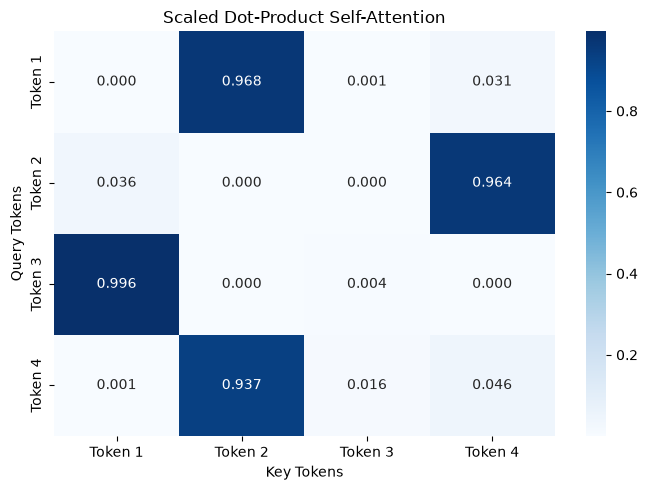

In [15]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    attention_weights,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=["Token 1", "Token 2", "Token 3", "Token 4"],
    yticklabels=["Token 1", "Token 2", "Token 3", "Token 4"]
)

plt.title("Scaled Dot-Product Self-Attention")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.tight_layout()
plt.savefig("4x4_attention_heatap.png")
plt.show()


In [16]:

assert attention_weights.shape == (4, 4)
assert output.shape == (4, 8)
assert np.allclose(attention_weights.sum(axis=-1), 1.0)

print("All shape and row-sum checks passed!")


All shape and row-sum checks passed!


## Task 2.3 — Why Divide by d_k ?

In [17]:

import numpy as np
import pandas as pd

np.random.seed(42)

def softmax(x, axis=-1):
    x_shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def attention_experiment(d_k, apply_scaling):
    # 32 query tokens and 32 key tokens
    Q = np.random.randn(32, d_k)
    K = np.random.randn(32, d_k)

    scores = Q @ K.T

    if apply_scaling:
        scores = scores / np.sqrt(d_k)

    weights = softmax(scores, axis=-1)

    # Average of maximum probability in each row
    avg_max_prob = np.mean(np.max(weights, axis=-1))

    # Entropy for each row, averaged across all rows
    entropy = -np.sum(
        weights * np.log(weights + 1e-12), axis=-1
    )
    avg_entropy = np.mean(entropy)

    return avg_max_prob, avg_entropy

results = []

for d_k in [4, 256]:
    for scaling in [False, True]:
        max_prob, entropy = attention_experiment(d_k, scaling)

        results.append({
            "d_k": d_k,
            "Scaling": "With scaling" if scaling else "Without scaling",
            "Average maximum probability": max_prob,
            "Average attention entropy": entropy
        })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


 d_k         Scaling  Average maximum probability  Average attention entropy
   4 Without scaling                       0.3797                     2.1740
   4    With scaling                       0.1302                     3.1108
 256 Without scaling                       0.8977                     0.2673
 256    With scaling                       0.1698                     3.0191



### Conclusion

The experiment demonstrates that increasing the key dimension can increase the magnitude of dot-product attention scores. Without scaling, softmax may become highly concentrated, resulting in a high maximum probability and low entropy. Dividing scores by sqrt(d_k) helps control their magnitude and generally produces a less concentrated attention distribution. The exact values depend on the random inputs.


## Task 2.4 — Self-Attention vs Luong Attention

In [18]:

import numpy as np

np.random.seed(42)

# Five encoder hidden states, each with 8 features
encoder_states = np.random.randn(5, 8)

# One decoder hidden state
decoder_state = np.random.randn(8)

# Calculate dot-product attention scores
scores = encoder_states @ decoder_state

# Convert scores into attention weights
weights = softmax(scores)

# Weighted sum of encoder hidden states
context = weights @ encoder_states

print("Encoder states shape:", encoder_states.shape)
print("Decoder state shape:", decoder_state.shape)
print("Attention scores shape:", scores.shape)
print("Attention weights:", weights)
print("Sum of attention weights:", weights.sum())
print("Context vector shape:", context.shape)
print("Context vector:", context)


Encoder states shape: (5, 8)
Decoder state shape: (8,)
Attention scores shape: (5,)
Attention weights: [0.04755781 0.10084111 0.00077742 0.61648294 0.23434072]
Sum of attention weights: 0.9999999999999999
Context vector shape: (8,)
Context vector: [-0.36327268 -0.13110175 -0.53344695 -0.03011265 -0.30693492 -0.8433026
 -0.78097616  1.1667187 ]



### Luong Attention vs Transformer Self-Attention

| Feature | Luong Dot-Product Attention | Transformer Self-Attention |
|---|---|---|
| Query (Q) | Decoder hidden state | Each token's projected representation |
| Key (K) | Encoder hidden states | Tokens in the same sequence |
| Value (V) | Encoder hidden states | Projected representations of the same sequence |
| What is attended over? | Encoder states, using the current decoder state | Other tokens in the same sequence |
| RNN requirement | Commonly used with encoder-decoder RNN architectures | Does not require an RNN |
| Parallelism | Decoder steps are commonly sequential in recurrent models | Token positions can be processed in parallel during training |
| Architecture | Often used between an encoder and decoder | Used inside Transformer encoder or decoder blocks |

### Conclusion

Luong attention helps a decoder focus on relevant encoder states while generating an output. Self-attention allows tokens within the same sequence to exchange contextual information. Both mechanisms use attention weights, but they differ in where their Queries, Keys and Values originate.


## Task 2.5 — Attention Is Order-Blind: Demonstration

In [19]:

# Use X, Wq, Wk and Wv from Task 2.2

def self_attention(X, Wq, Wk, Wv):
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv

    scores = Q @ K.T / np.sqrt(Q.shape[-1])
    weights = softmax(scores, axis=-1)

    return weights @ V

# Original output
original_output = self_attention(X, Wq, Wk, Wv)

# Shuffle the four token rows
permutation = np.array([2, 0, 3, 1])
X_shuffled = X[permutation]

# Calculate output for shuffled input
shuffled_output = self_attention(X_shuffled, Wq, Wk, Wv)

# Expected output: same permutation applied to original output
expected_output = original_output[permutation]

print("Permutation:", permutation)
print("\nOriginal output shape:", original_output.shape)
print("Shuffled output shape:", shuffled_output.shape)

print(
    "\nOutputs follow the same permutation:",
    np.allclose(shuffled_output, expected_output)
)

print(
    "Maximum absolute difference:",
    np.max(np.abs(shuffled_output - expected_output))
)


Permutation: [2 0 3 1]

Original output shape: (4, 8)
Shuffled output shape: (4, 8)

Outputs follow the same permutation: True
Maximum absolute difference: 1.7763568394002505e-15


## Task 2.6 — Verify Attention Against a Real DistilBERT Model

In [20]:

import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tok = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    attn_implementation="eager"
)

model.eval()

print(model.distilbert.transformer.layer[0].attention)


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1682.93it/s]

DistilBertSelfAttention(
  (q_lin): Linear(in_features=768, out_features=768, bias=True)
  (k_lin): Linear(in_features=768, out_features=768, bias=True)
  (v_lin): Linear(in_features=768, out_features=768, bias=True)
  (out_lin): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)


In [21]:

text = "The animal did not cross the street because it was too tired."

inputs = tok(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(
        **inputs,
        output_hidden_states=True,
        output_attentions=True
    )

hidden_states = outputs.hidden_states[0]

actual_attention = outputs.attentions[0][0, 0]

print("Input IDs shape:", inputs["input_ids"].shape)
print("Hidden states shape:", hidden_states.shape)
print("All attention tensors:")

for i, attention in enumerate(outputs.attentions):
    print(f"Layer {i}: {tuple(attention.shape)}")

print("\nActual layer-0, head-0 shape:", actual_attention.shape)


Input IDs shape: torch.Size([1, 15])
Hidden states shape: torch.Size([1, 15, 768])
All attention tensors:
Layer 0: (1, 12, 15, 15)
Layer 1: (1, 12, 15, 15)
Layer 2: (1, 12, 15, 15)
Layer 3: (1, 12, 15, 15)
Layer 4: (1, 12, 15, 15)
Layer 5: (1, 12, 15, 15)

Actual layer-0, head-0 shape: torch.Size([15, 15])


In [22]:

attention_layer = model.distilbert.transformer.layer[0].attention

# Calculate Query and Key projections
Q = attention_layer.q_lin(hidden_states)
K = attention_layer.k_lin(hidden_states)

batch_size, seq_length, hidden_size = Q.shape
num_heads = model.config.n_heads
head_dim = hidden_size // num_heads

# Split into 12 heads of 64 dimensions each
Q = Q.view(
    batch_size, seq_length, num_heads, head_dim
).transpose(1, 2)

K = K.view(
    batch_size, seq_length, num_heads, head_dim
).transpose(1, 2)

print("Q shape after splitting:", Q.shape)
print("K shape after splitting:", K.shape)

# Calculate scaled dot-product scores
scores = torch.matmul(Q, K.transpose(-1, -2))
scores = scores / np.sqrt(head_dim)

# Apply padding mask if any
padding_mask = inputs["attention_mask"] == 0
padding_mask = padding_mask[:, None, None, :]

scores = scores.masked_fill(
    padding_mask,
    torch.finfo(scores.dtype).min
)

# Convert scores into attention probabilities
manual_attention = torch.softmax(scores, dim=-1)

# Select batch 0, head 0
manual_attention = manual_attention[0, 0]

print("Manual attention shape:", manual_attention.shape)
print("Actual attention shape:", actual_attention.shape)


Q shape after splitting: torch.Size([1, 12, 15, 64])
K shape after splitting: torch.Size([1, 12, 15, 64])
Manual attention shape: torch.Size([15, 15])
Actual attention shape: torch.Size([15, 15])


# Task 3: Multi-Head Attention, Positional Encoding & Layer Normalization



## Task 3.1: Multi-Head Attention

**Objective:** Explain why Transformers use multiple attention heads instead of a single attention pattern.

**Expected Output:** An explanation of head dimensions, independent Query, Key and Value projections, concatenation, and the output projection.

A single attention head learns one attention pattern, while multiple heads can learn different patterns in parallel. In DistilBERT, the hidden size is 768 and there are 12 attention heads, so each head has 64 dimensions. Each head uses its own Query, Key and Value projections to calculate attention in a different representation subspace. The head outputs are concatenated and passed through an output projection to combine their information. Using multiple heads allows the model to represent different token relationships, with total computation remaining approximately comparable to one large attention operation at the same hidden size.


## Task 3.2 — Extract and Plot Real Attention Heads

In [23]:

import torch
import matplotlib.pyplot as plt
import seaborn as sns

text = "The animal did not cross the street because it was too tired."

inputs = tok(text, return_tensors="pt")
tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])

model.eval()

with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True
    )

attentions = outputs.attentions

print("Number of layers:", len(attentions))

for layer_index, attention in enumerate(attentions):
    print(f"Layer {layer_index} shape: {tuple(attention.shape)}")

print("\nTokens:")
print(tokens)


Number of layers: 6
Layer 0 shape: (1, 12, 15, 15)
Layer 1 shape: (1, 12, 15, 15)
Layer 2 shape: (1, 12, 15, 15)
Layer 3 shape: (1, 12, 15, 15)
Layer 4 shape: (1, 12, 15, 15)
Layer 5 shape: (1, 12, 15, 15)

Tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


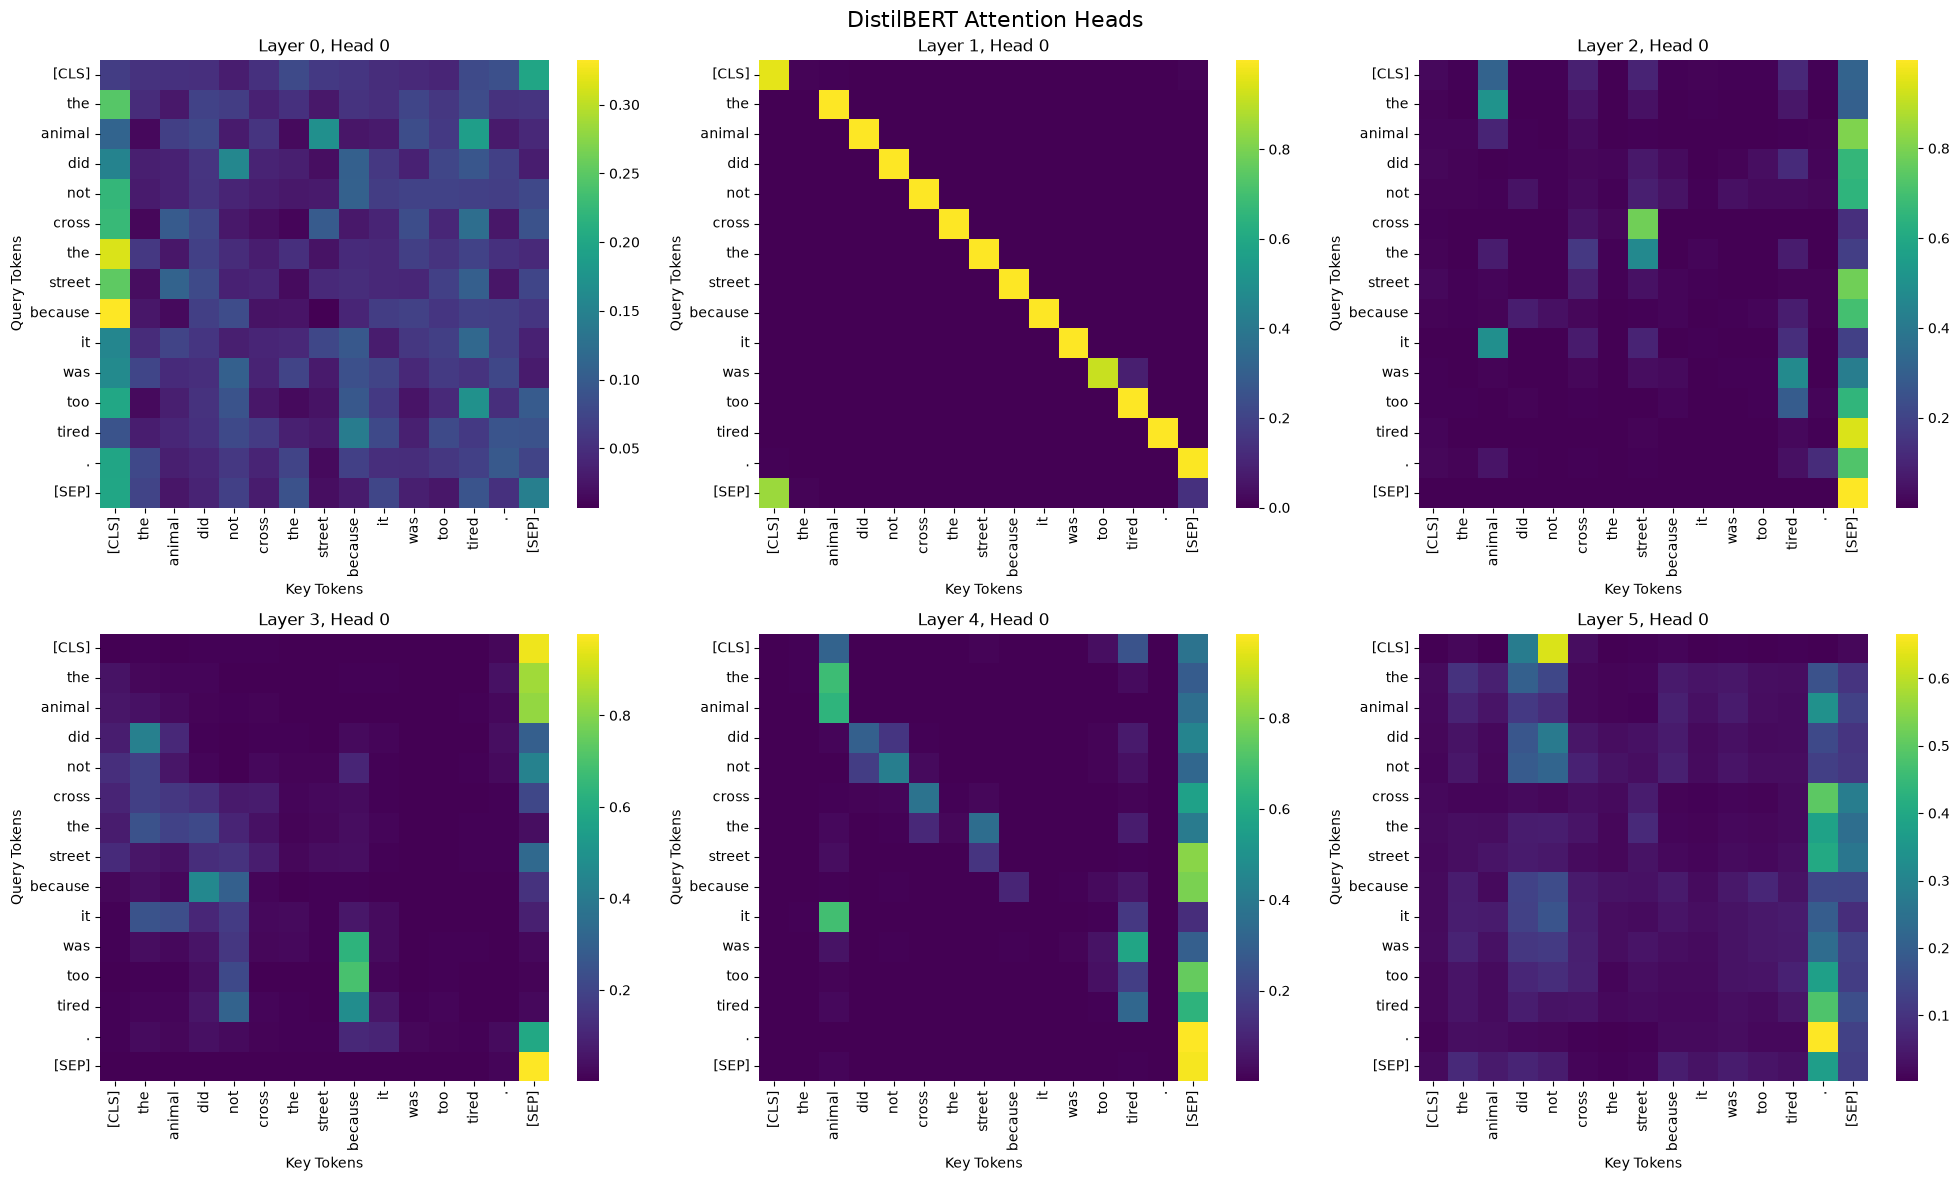

In [24]:

selected_layers = [0, 1, 2, 3, 4, 5]
selected_head = 0

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for ax, layer_index in zip(axes.flat, selected_layers):
    attention_matrix = (
        attentions[layer_index][0, selected_head]
        .cpu()
        .numpy()
    )

    sns.heatmap(
        attention_matrix,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        annot=False,
        ax=ax
    )

    ax.set_title(
        f"Layer {layer_index}, Head {selected_head}"
    )
    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("DistilBERT Attention Heads", fontsize=16)
plt.tight_layout()
plt.savefig("6_attention_head_heatmap.png")
plt.show()


## Task 3.3 — Head Diversity Measurement

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Get the first and last Transformer layers
first_layer = attentions[0][0].detach().cpu().numpy()
last_layer = attentions[-1][0].detach().cpu().numpy()

print("First layer attention shape:", first_layer.shape)
print("Last layer attention shape:", last_layer.shape)

def calculate_attention_entropy(layer_attention):
    # Avoid log(0) by adding a very small value
    epsilon = 1e-12

    # Entropy for each attention distribution
    entropy = -np.sum(
        layer_attention * np.log(layer_attention + epsilon),
        axis=-1
    )

    # Average across all query tokens
    average_entropy = entropy.mean(axis=-1)

    return average_entropy

first_entropy = calculate_attention_entropy(first_layer)
last_entropy = calculate_attention_entropy(last_layer)

print("\nFirst Layer — Average Entropy per Head")
for head, value in enumerate(first_entropy):
    print(f"Head {head}: {value:.4f}")

print("\nLast Layer — Average Entropy per Head")
for head, value in enumerate(last_entropy):
    print(f"Head {head}: {value:.4f}")

First layer attention shape: (12, 15, 15)
Last layer attention shape: (12, 15, 15)

First Layer — Average Entropy per Head
Head 0: 2.4939
Head 1: 2.0654
Head 2: 0.5533
Head 3: 1.2512
Head 4: 2.3135
Head 5: 2.1365
Head 6: 2.2454
Head 7: 1.6157
Head 8: 1.7954
Head 9: 1.2444
Head 10: 0.6994
Head 11: 1.8173

Last Layer — Average Entropy per Head
Head 0: 2.0346
Head 1: 1.8619
Head 2: 2.2673
Head 3: 1.8916
Head 4: 1.9279
Head 5: 1.9788
Head 6: 1.9930
Head 7: 1.7625
Head 8: 1.9481
Head 9: 2.2913
Head 10: 2.0655
Head 11: 2.0924


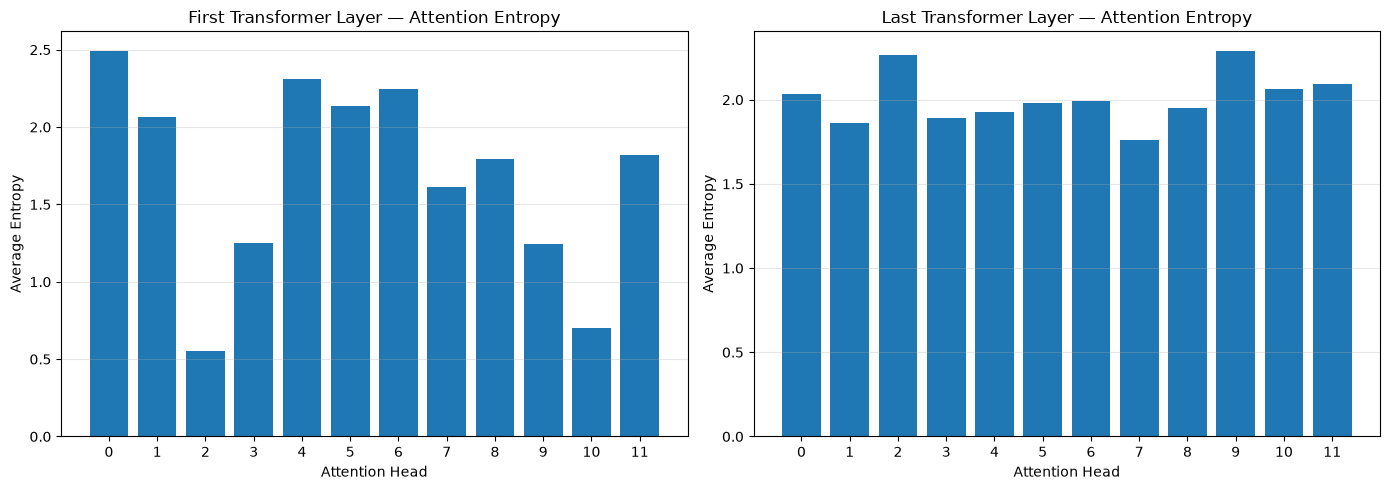

In [26]:
head_numbers = np.arange(len(first_entropy))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# First layer
axes[0].bar(head_numbers, first_entropy)
axes[0].set_title("First Transformer Layer — Attention Entropy")
axes[0].set_xlabel("Attention Head")
axes[0].set_ylabel("Average Entropy")
axes[0].set_xticks(head_numbers)
axes[0].grid(axis="y", alpha=0.3)

# Last layer
axes[1].bar(head_numbers, last_entropy)
axes[1].set_title("Last Transformer Layer — Attention Entropy")
axes[1].set_xlabel("Attention Head")
axes[1].set_ylabel("Average Entropy")
axes[1].set_xticks(head_numbers)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("attention_entropy.png")
plt.show()

## Task 3.4 — Sinusoidal Positional Encoding

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Define sequence length and embedding dimension
max_positions = 50
d_model = 128

def positional_encoding(max_positions, d_model):
    # Create position indices: 0 to 49
    positions = np.arange(max_positions)[:, np.newaxis]

    # Create dimension indices: 0 to 127
    dimensions = np.arange(d_model)[np.newaxis, :]

    # Calculate the angle rates
    angle_rates = 1 / np.power(
        10000,
        (2 * (dimensions // 2)) / d_model
    )

    # Calculate angles for each position and dimension
    angles = positions * angle_rates

    # Create the positional encoding matrix
    encoding = np.zeros((max_positions, d_model))

    # Apply sine to even dimensions
    encoding[:, 0::2] = np.sin(angles[:, 0::2])

    # Apply cosine to odd dimensions
    encoding[:, 1::2] = np.cos(angles[:, 1::2])

    return encoding


pe = positional_encoding(max_positions, d_model)

print("Positional Encoding Shape:", pe.shape)
print("\nFirst 5 positions, first 8 dimensions:")
print(np.round(pe[:5, :8], 4))

Positional Encoding Shape: (50, 128)

First 5 positions, first 8 dimensions:
[[ 0.      1.      0.      1.      0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.7617  0.6479  0.6816  0.7318  0.6047  0.7965]
 [ 0.9093 -0.4161  0.987  -0.1604  0.9975  0.0709  0.9632  0.2687]
 [ 0.1411 -0.99    0.5173 -0.8558  0.7783 -0.6279  0.9296 -0.3685]
 [-0.7568 -0.6536 -0.3167 -0.9485  0.1415 -0.9899  0.5176 -0.8556]]


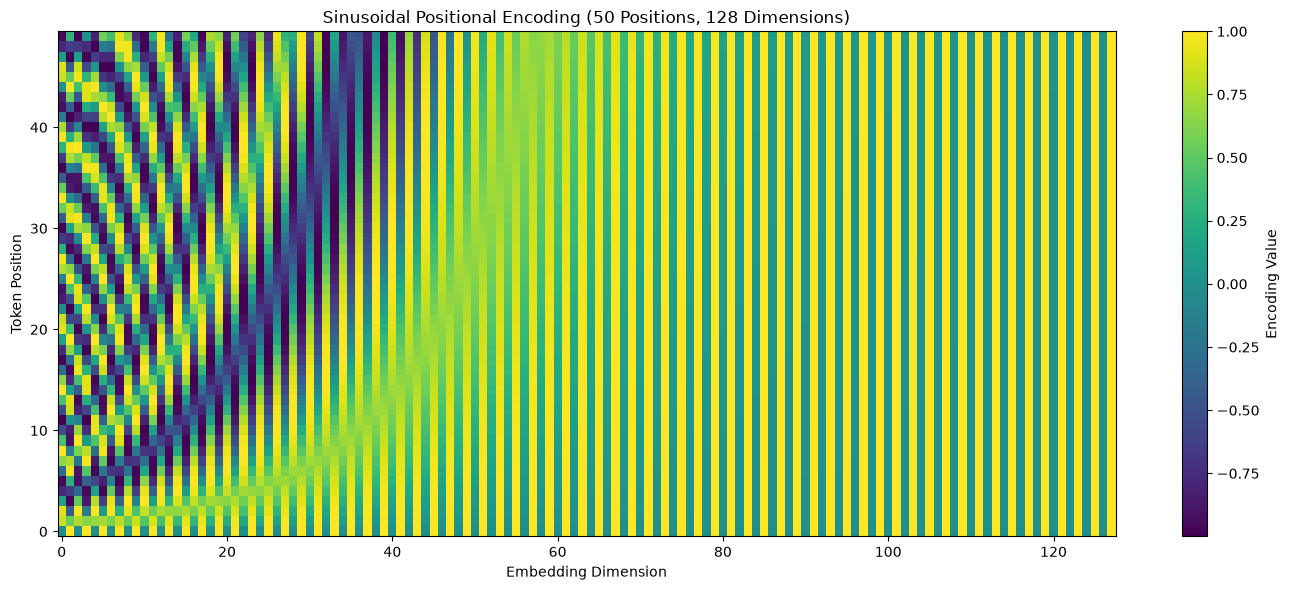

In [28]:
plt.figure(figsize=(14, 6))

plt.imshow(
    pe,
    aspect="auto",
    cmap="viridis",
    origin="lower"
)

plt.colorbar(label="Encoding Value")
plt.xlabel("Embedding Dimension")
plt.ylabel("Token Position")
plt.title("Sinusoidal Positional Encoding (50 Positions, 128 Dimensions)")

plt.tight_layout()
plt.savefig("positional_encoding.png")
plt.show()

 ## Task 3.5 — Effect of Positional Encoding on Word Similarity

In [29]:
import numpy as np

# Create a reproducible word embedding
np.random.seed(42)
word_embedding = np.random.randn(d_model)

# Select positions 3 and 20
position_3 = pe[3]
position_20 = pe[20]

# Representations without positional encoding
embedding_at_3_without_pe = word_embedding.copy()
embedding_at_20_without_pe = word_embedding.copy()

# Representations with positional encoding
embedding_at_3_with_pe = word_embedding + position_3
embedding_at_20_with_pe = word_embedding + position_20

# Cosine similarity function
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b)
    )

# Calculate similarities
similarity_without_pe = cosine_similarity(
    embedding_at_3_without_pe,
    embedding_at_20_without_pe
)

similarity_with_pe = cosine_similarity(
    embedding_at_3_with_pe,
    embedding_at_20_with_pe
)

print("Cosine similarity WITHOUT positional encoding:",
      round(similarity_without_pe, 4))

print("Cosine similarity WITH positional encoding:",
      round(similarity_with_pe, 4))

Cosine similarity WITHOUT positional encoding: 1.0
Cosine similarity WITH positional encoding: 0.8595


## Task 3.6 — Learned Positional Embeddings

In [30]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from transformers import AutoModel

# Load BERT, which uses learned positional embeddings
bert_model = AutoModel.from_pretrained("bert-base-uncased")

# Extract the learned position embedding matrix
position_embeddings = (
    bert_model.embeddings.position_embeddings.weight
    .detach()
    .cpu()
    .numpy()
)

# Select the first 64 positions
position_embeddings_64 = position_embeddings[:64]

print("Full positional embedding shape:", position_embeddings.shape)
print("First 64 positions shape:", position_embeddings_64.shape)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 545.13it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Full positional embedding shape: (512, 768)
First 64 positions shape: (64, 768)


Cosine similarity matrix shape: (64, 64)


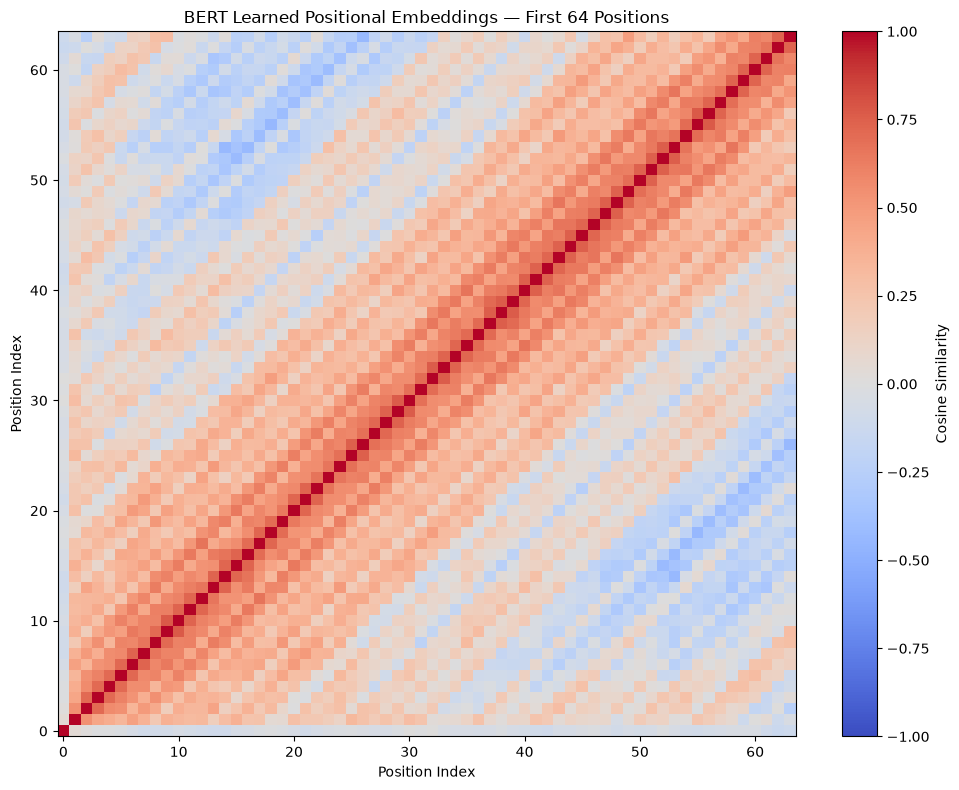

In [31]:
# Normalize each positional embedding
norms = np.linalg.norm(position_embeddings_64, axis=1, keepdims=True)
normalized_embeddings = position_embeddings_64 / np.maximum(norms, 1e-12)

# Calculate pairwise cosine similarities
similarity_matrix = normalized_embeddings @ normalized_embeddings.T

print("Cosine similarity matrix shape:", similarity_matrix.shape)

plt.figure(figsize=(10, 8))

plt.imshow(
    similarity_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Cosine Similarity")
plt.xlabel("Position Index")
plt.ylabel("Position Index")
plt.title("BERT Learned Positional Embeddings — First 64 Positions")

plt.tight_layout()
plt.savefig("position_enc_matrix.png")
plt.show()

## Task 3.7 — Implement Layer Normalization from Scratch

In [32]:
import numpy as np

# Create a reproducible input matrix: 4 samples, 8 features each
np.random.seed(42)
X = np.random.randn(4, 8)

def layer_norm_numpy(X, eps=1e-5):
    # Calculate mean for each row
    mean = np.mean(X, axis=-1, keepdims=True)

    # Calculate variance for each row
    variance = np.var(X, axis=-1, keepdims=True)

    # Normalize the input
    X_normalized = (X - mean) / np.sqrt(variance + eps)

    return X_normalized

X_normalized = layer_norm_numpy(X)

print("Original matrix shape:", X.shape)
print("\nNormalized matrix:\n", np.round(X_normalized, 4))

print("\nMean of each normalized row:")
print(np.mean(X_normalized, axis=-1))

print("\nStandard deviation of each normalized row:")
print(np.std(X_normalized, axis=-1))

Original matrix shape: (4, 8)

Normalized matrix:
 [[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]

Mean of each normalized row:
[-8.32667268e-17  2.77555756e-17 -5.55111512e-17  2.77555756e-17]

Standard deviation of each normalized row:
[0.99998939 0.99999209 0.99999424 0.99999325]


In [33]:
import torch
import torch.nn as nn

# Convert NumPy input to a PyTorch tensor
X_torch = torch.tensor(X, dtype=torch.float32)

# Create LayerNorm for 8 features
layer_norm_torch = nn.LayerNorm(8, eps=1e-5)

# Disable gradient calculation for comparison
with torch.no_grad():
    output_torch = layer_norm_torch(X_torch).numpy()

# Calculate NumPy output using float32 input
output_numpy = layer_norm_numpy(
    X.astype(np.float32),
    eps=1e-5
)

print("PyTorch output:\n", np.round(output_torch, 4))
print("\nNumPy output:\n", np.round(output_numpy, 4))

print("\nOutputs match:",
      np.allclose(output_numpy, output_torch, atol=1e-5))

PyTorch output:
 [[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]

NumPy output:
 [[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]

Outputs match: True


## Task 3.8 — Batch Normalization vs Layer Normalization

##

In [34]:
import torch
import torch.nn as nn
import numpy as np

# Reuse the same 4 × 8 matrix from Task 3.7
X_torch = torch.tensor(X, dtype=torch.float32)

# LayerNorm: normalize 8 features within each token
layer_norm = nn.LayerNorm(8, eps=1e-5)

# BatchNorm1d: normalize each feature across the 4 tokens
batch_norm = nn.BatchNorm1d(
    num_features=8,
    eps=1e-5,
    affine=False,
    track_running_stats=False
)

# Use evaluation mode to avoid updating BatchNorm running statistics
layer_norm.eval()
batch_norm.eval()

with torch.no_grad():
    layer_output = layer_norm(X_torch)
    batch_output = batch_norm(X_torch)

print("Input shape:", X_torch.shape)
print("LayerNorm output shape:", layer_output.shape)
print("BatchNorm output shape:", batch_output.shape)

print("\nLayerNorm — mean per token:")
print(torch.mean(layer_output, dim=1))

print("\nLayerNorm — standard deviation per token:")
print(torch.std(layer_output, dim=1, unbiased=False))

print("\nBatchNorm — mean per token:")
print(torch.mean(batch_output, dim=1))

print("\nBatchNorm — standard deviation per token:")
print(torch.std(batch_output, dim=1, unbiased=False))

print("\nBatchNorm — mean per feature:")
print(torch.mean(batch_output, dim=0))

Input shape: torch.Size([4, 8])
LayerNorm output shape: torch.Size([4, 8])
BatchNorm output shape: torch.Size([4, 8])

LayerNorm — mean per token:
tensor([-1.1176e-08, -1.6764e-08,  1.4901e-08, -2.9802e-08])

LayerNorm — standard deviation per token:
tensor([1.0000, 1.0000, 1.0000, 1.0000])

BatchNorm — mean per token:
tensor([ 0.6523, -0.3536, -0.1908, -0.1078])

BatchNorm — standard deviation per token:
tensor([1.0439, 0.8670, 0.9942, 0.7560])

BatchNorm — mean per feature:
tensor([-4.4703e-08, -1.4901e-08, -5.9605e-08,  7.4506e-09,  0.0000e+00,
        -2.9802e-08,  1.4901e-08, -2.9802e-08])


In [35]:
# Access DistilBERT's embedding LayerNorm
embedding_layer_norm = model.distilbert.embeddings.LayerNorm

gamma = embedding_layer_norm.weight.detach().cpu()
beta = embedding_layer_norm.bias.detach().cpu()

print("Gamma (weight) shape:", tuple(gamma.shape))
print("Beta (bias) shape:", tuple(beta.shape))

print("\nFirst 10 gamma values:")
print(gamma[:10].numpy())

print("\nFirst 10 beta values:")
print(beta[:10].numpy())

Gamma (weight) shape: (768,)
Beta (bias) shape: (768,)

First 10 gamma values:
[0.84453845 0.7973702  0.7331022  0.7594067  0.8013367  0.7860578
 0.81700695 0.81767267 0.8369104  0.7072889 ]

First 10 beta values:
[ 0.04434412  0.06143165  0.06922504  0.08740238 -0.05842698 -0.1601391
  0.14428861 -0.06059985 -0.02787716  0.12216391]


### LayerNorm vs BatchNorm

| Feature | Layer Normalization | Batch Normalization |
|---|---|---|
| Normalization axis | Features within each token | Each feature across batch samples |
| Batch-size dependence | Does not depend on other samples in the batch | Depends on batch statistics during training |
| Variable-length sequences | Works naturally per token; padding still needs masking where appropriate | Padding and batch composition can affect statistics |
| Transformer usage | Commonly used in Transformer blocks | Not the standard normalization in Transformer blocks |

### Observation

LayerNorm normalizes each token independently, whereas BatchNorm
normalizes each feature across the batch. LayerNorm is well suited
to Transformers because its normalization does not depend on the
other samples in the batch. Padding positions still require appropriate
attention masking.

DistilBERT's embedding LayerNorm has learnable gamma (weight) and
beta (bias) vectors, each of shape (768,).

# Task 4: Transformer Encoder Architecture & Masked Self-Attention


## Task 4.1: Transformer Encoder Architecture

### Encoder Block

The input tokens are converted into token embeddings, and positional
information is added to represent their positions in the sequence.

The input then passes through six stacked Transformer encoder blocks
in DistilBERT. Each block contains:

1. Multi-head self-attention.
2. A residual connection followed by Layer Normalization.
3. A position-wise feed-forward network that expands the hidden
   dimension from 768 to 3072, applies a non-linearity, and projects
   it back from 3072 to 768.
4. Another residual connection followed by Layer Normalization.

### Bidirectional Attention

An encoder allows each token to attend to tokens on both its left
and right sides, subject to the attention mask. This is called
bidirectional self-attention.

### DistilBERT

DistilBERT contains six Transformer encoder layers. Each layer applies
multi-head self-attention and a feed-forward network, with residual
connections and Layer Normalization.

## Task 4.2 — Print and Inspect the Real DistilBERT Encoder

In [36]:
# Print the DistilBERT architecture
if hasattr(model, "distilbert"):
    encoder = model.distilbert
else:
    encoder = model

print(encoder)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [37]:
# Display important modules and their purposes
module_keywords = [
    "word_embeddings",
    "position_embeddings",
    "LayerNorm",
    "q_lin",
    "k_lin",
    "v_lin",
    "out_lin",
    "lin1",
    "lin2",
    "sa_layer_norm",
    "output_layer_norm"
]

print("Important DistilBERT modules:\n")

for name, module in encoder.named_modules():
    if name and any(keyword in name for keyword in module_keywords):
        print(f"{name:55s} -> {module.__class__.__name__}")

Important DistilBERT modules:

embeddings.word_embeddings                              -> Embedding
embeddings.position_embeddings                          -> Embedding
embeddings.LayerNorm                                    -> LayerNorm
transformer.layer.0.attention.q_lin                     -> Linear
transformer.layer.0.attention.k_lin                     -> Linear
transformer.layer.0.attention.v_lin                     -> Linear
transformer.layer.0.attention.out_lin                   -> Linear
transformer.layer.0.sa_layer_norm                       -> LayerNorm
transformer.layer.0.ffn.lin1                            -> Linear
transformer.layer.0.ffn.lin2                            -> Linear
transformer.layer.0.output_layer_norm                   -> LayerNorm
transformer.layer.1.attention.q_lin                     -> Linear
transformer.layer.1.attention.k_lin                     -> Linear
transformer.layer.1.attention.v_lin                     -> Linear
transformer.layer.1.attention.

In [38]:
# Inspect the embedding and feed-forward dimensions
config = encoder.config

print("Hidden dimension:", config.dim)
print("Number of attention heads:", config.n_heads)
print("Number of Transformer layers:", config.n_layers)
print("Feed-forward dimension:", config.hidden_dim)

# Inspect the first Transformer layer
first_transformer_layer = encoder.transformer.layer[0]

print("\nFeed-forward expansion layer:")
print(first_transformer_layer.ffn.lin1)

print("\nFeed-forward projection layer:")
print(first_transformer_layer.ffn.lin2)

print("\nAttention projections:")
print(first_transformer_layer.attention.q_lin)
print(first_transformer_layer.attention.k_lin)
print(first_transformer_layer.attention.v_lin)
print(first_transformer_layer.attention.out_lin)

Hidden dimension: 768
Number of attention heads: 12
Number of Transformer layers: 6
Feed-forward dimension: 3072

Feed-forward expansion layer:
Linear(in_features=768, out_features=3072, bias=True)

Feed-forward projection layer:
Linear(in_features=3072, out_features=768, bias=True)

Attention projections:
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=768, bias=True)


## Task 4.3 — Where Do the Parameters Live?

In [39]:
from collections import defaultdict

# Store parameter counts for each group
parameter_counts = defaultdict(int)

for name, parameter in model.named_parameters():
    name_lower = name.lower()

    if "embeddings" in name_lower:
        group = "Embeddings"

    elif any(term in name_lower for term in [
        "layernorm", "layer_norm", "sa_layer_norm",
        "output_layer_norm"
    ]):
        group = "Layer Normalization"

    elif any(term in name_lower for term in [
        "pre_classifier", "classifier"
    ]):
        group = "Classification Head"

    elif any(term in name_lower for term in [
        "q_lin", "k_lin", "v_lin", "out_lin"
    ]):
        group = "Attention"

    elif any(term in name_lower for term in [
        "ffn.lin1", "ffn.lin2"
    ]):
        group = "Feed-Forward"

    else:
        group = "Other"

    parameter_counts[group] += parameter.numel()

# Count all model parameters
total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

print(f"Total model parameters: {total_parameters:,}\n")

print(f"{'Component':<25} {'Parameters':>15} {'Percentage':>12}")
print("-" * 55)

for group, count in sorted(
    parameter_counts.items(),
    key=lambda item: item[1],
    reverse=True
):
    percentage = (count / total_parameters) * 100

    print(f"{group:<25} {count:>15,} {percentage:>11.2f}%")

print("\nGrouped total:", f"{sum(parameter_counts.values()):,}")
print("Matches model total:",
      sum(parameter_counts.values()) == total_parameters)

Total model parameters: 66,955,010

Component                      Parameters   Percentage
-------------------------------------------------------
Feed-Forward                   28,334,592       42.32%
Embeddings                     23,835,648       35.60%
Attention                      14,174,208       21.17%
Classification Head               592,130        0.88%
Layer Normalization                18,432        0.03%

Grouped total: 66,955,010
Matches model total: True


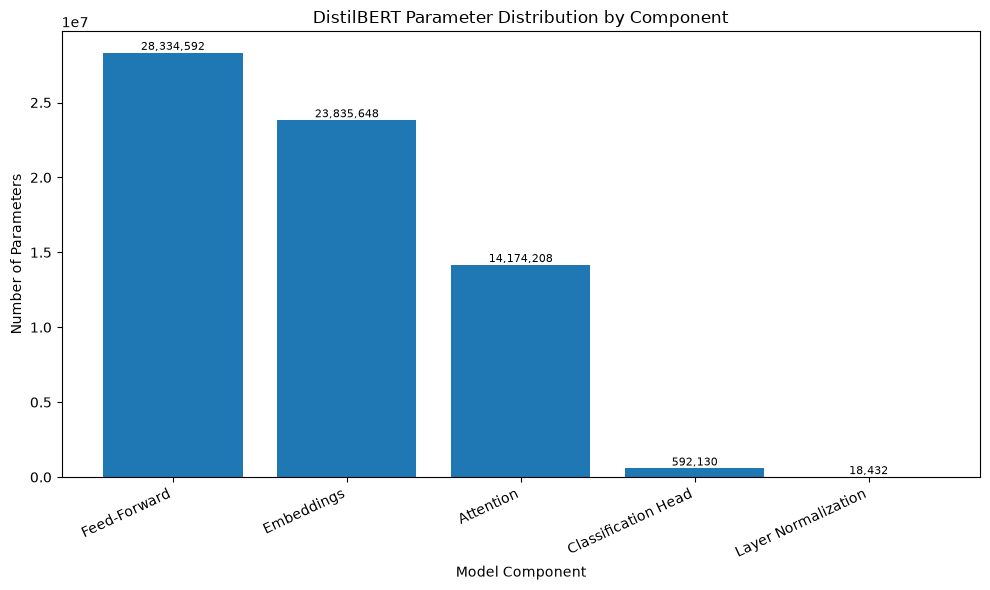

In [40]:
import matplotlib.pyplot as plt

groups = list(parameter_counts.keys())
counts = [parameter_counts[group] for group in groups]

# Sort components by parameter count
sorted_data = sorted(
    zip(groups, counts),
    key=lambda item: item[1],
    reverse=True
)

groups = [item[0] for item in sorted_data]
counts = [item[1] for item in sorted_data]

plt.figure(figsize=(10, 6))

bars = plt.bar(groups, counts)

plt.title("DistilBERT Parameter Distribution by Component")
plt.xlabel("Model Component")
plt.ylabel("Number of Parameters")
plt.xticks(rotation=25, ha="right")

# Display parameter counts above bars
for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.savefig("component_dist.png")
plt.show()

## Task 4.4 — Bidirectional Attention Heatmap

Attention matrix shape: (15, 15)
Number of tokens: 15
Tokens: ['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


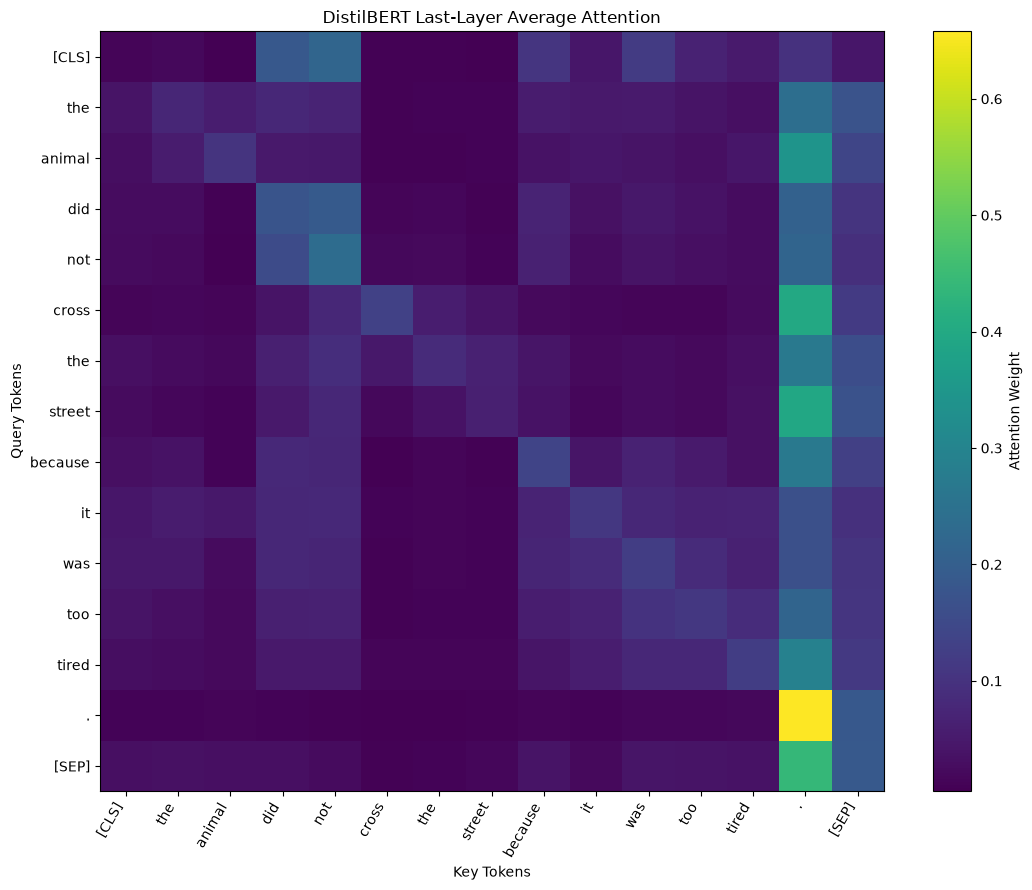

In [41]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Sentence to analyze
sentence = "The animal did not cross the street because it was too tired."

# Tokenize the sentence
inputs = tok(sentence, return_tensors="pt")

# Use the same device as the model
device = next(model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

# Get attention weights
model.eval()
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# Get attention from the last layer
last_layer_attention = outputs.attentions[-1][0]

# Average attention across all heads
average_attention = last_layer_attention.mean(dim=0).cpu().numpy()

# Get readable token labels
tokens = tok.convert_ids_to_tokens(
    inputs["input_ids"][0].detach().cpu().tolist()
)

print("Attention matrix shape:", average_attention.shape)
print("Number of tokens:", len(tokens))
print("Tokens:", tokens)

# Plot heatmap
plt.figure(figsize=(11, 9))

plt.imshow(
    average_attention,
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(label="Attention Weight")
plt.xticks(range(len(tokens)), tokens, rotation=60, ha="right")
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.title("DistilBERT Last-Layer Average Attention")
plt.tight_layout()
plt.savefig("avg_attention_heatmap.png")
plt.show()

In [42]:
# Values above and below the main diagonal
upper_triangle = np.triu(average_attention, k=1)
lower_triangle = np.tril(average_attention, k=-1)

print("Maximum attention above diagonal:",
      upper_triangle.max())

print("Maximum attention below diagonal:",
      lower_triangle.max())

print("Non-zero attention above diagonal:",
      np.count_nonzero(upper_triangle > 1e-8))

print("Non-zero attention below diagonal:",
      np.count_nonzero(lower_triangle > 1e-8))

Maximum attention above diagonal: 0.39907905
Maximum attention below diagonal: 0.4407414
Non-zero attention above diagonal: 105
Non-zero attention below diagonal: 105


## Task 4.6 — Implement Causal Masked Self-Attention from Scratch

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Six tokens
seq_len = 6

# Create a mask with -infinity above the diagonal and 0 elsewhere
causal_mask = np.triu(
    np.full((seq_len, seq_len), -np.inf),
    k=1
)

print("Causal Mask:\n")
print(causal_mask)

Causal Mask:

[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


In [44]:
# Reproducible random attention scores
np.random.seed(42)
scores = np.random.randn(seq_len, seq_len)

# Apply causal mask BEFORE softmax
masked_scores = scores + causal_mask

def softmax(x, axis=-1):
    # Numerically stable softmax
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

# Convert masked scores into attention probabilities
causal_attention = softmax(masked_scores, axis=-1)

print("Masked attention matrix:\n")
print(np.round(causal_attention, 4))

print("\nRow sums:")
print(causal_attention.sum(axis=-1))

print("\nMaximum value above diagonal:")
print(np.triu(causal_attention, k=1).max())

Masked attention matrix:

[[1.     0.     0.     0.     0.     0.    ]
 [0.6925 0.3075 0.     0.     0.     0.    ]
 [0.7963 0.0923 0.1114 0.     0.     0.    ]
 [0.0698 0.0422 0.7498 0.1382 0.     0.    ]
 [0.1444 0.2781 0.0787 0.3623 0.1365 0.    ]
 [0.0506 0.5887 0.0911 0.0321 0.2102 0.0272]]

Row sums:
[1. 1. 1. 1. 1. 1.]

Maximum value above diagonal:
0.0


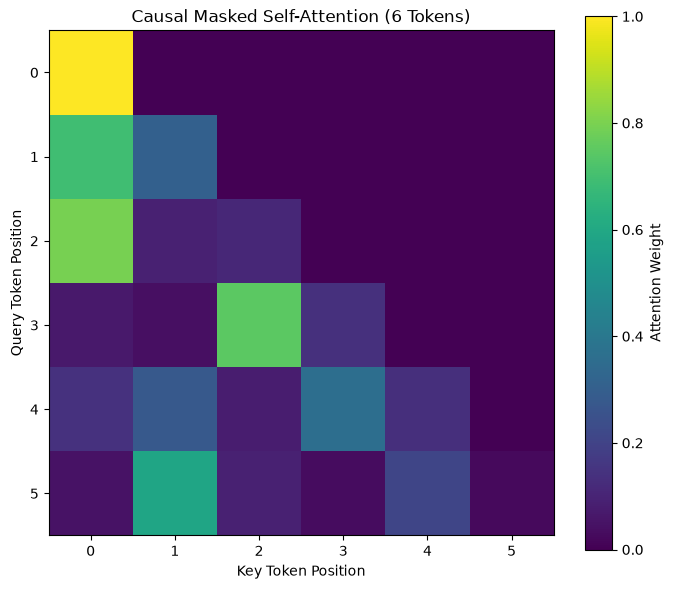

In [45]:
plt.figure(figsize=(7, 6))

plt.imshow(
    causal_attention,
    cmap="viridis",
    vmin=0,
    vmax=1,
    origin="upper"
)

plt.colorbar(label="Attention Weight")
plt.xlabel("Key Token Position")
plt.ylabel("Query Token Position")
plt.title("Causal Masked Self-Attention (6 Tokens)")

plt.xticks(range(seq_len))
plt.yticks(range(seq_len))
plt.tight_layout()
plt.savefig("causal_selfattention_matrix.png")
plt.show()

## Task 4.7 — Causal Mask in a Real GPT-2 Model

In [46]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

# Load pretrained GPT-2 with eager attention
gpt2_name = "openai-community/gpt2"

gpt2_tokenizer = AutoTokenizer.from_pretrained(gpt2_name)

gpt2_model = AutoModelForCausalLM.from_pretrained(
    gpt2_name,
    attn_implementation="eager"
)

gpt2_model.eval()

# Input sentence
sentence = "The animal did not cross the street because it was tired."

inputs_gpt2 = gpt2_tokenizer(
    sentence,
    return_tensors="pt"
)

# Use the same device as the model
device = next(gpt2_model.parameters()).device
inputs_gpt2 = {
    key: value.to(device)
    for key, value in inputs_gpt2.items()
}

# Extract attention weights
with torch.no_grad():
    outputs_gpt2 = gpt2_model(
        **inputs_gpt2,
        output_attentions=True
    )

# Last layer, first example, first attention head
attention = (
    outputs_gpt2.attentions[-1][0, 0]
    .detach()
    .cpu()
    .numpy()
)

tokens_gpt2 = gpt2_tokenizer.convert_ids_to_tokens(
    inputs_gpt2["input_ids"][0].detach().cpu().tolist()
)

print("Number of layers:", len(outputs_gpt2.attentions))
print("Attention matrix shape:", attention.shape)
print("Tokens:", tokens_gpt2)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 227.44it/s]

Number of layers: 12
Attention matrix shape: (12, 12)
Tokens: ['The', 'Ġanimal', 'Ġdid', 'Ġnot', 'Ġcross', 'Ġthe', 'Ġstreet', 'Ġbecause', 'Ġit', 'Ġwas', 'Ġtired', '.']


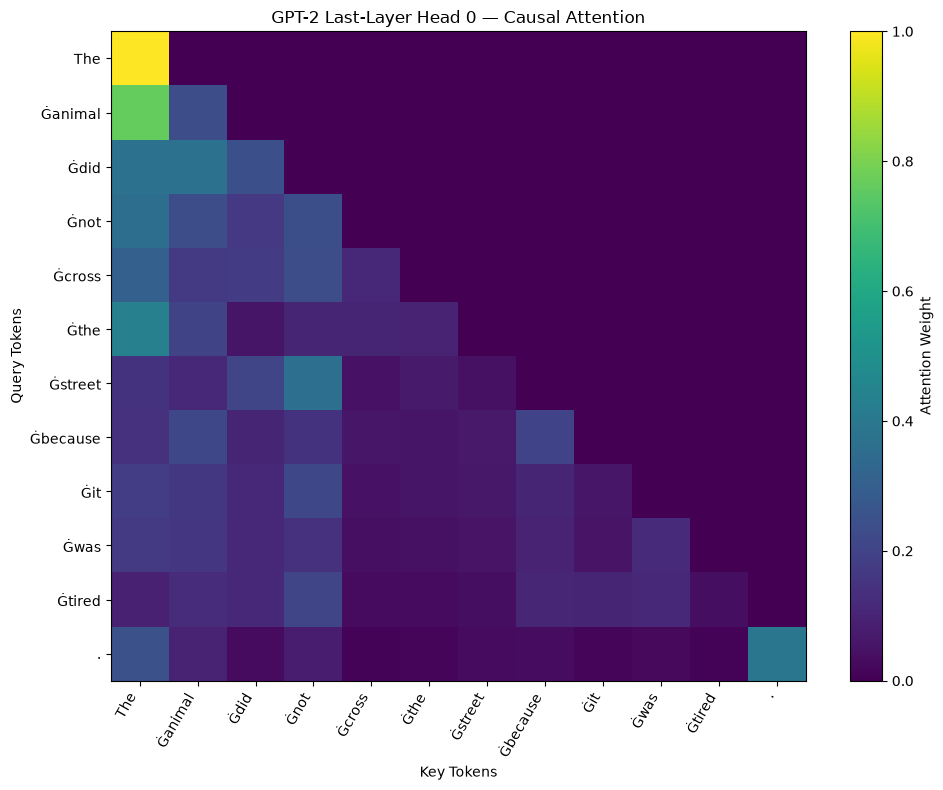

In [47]:
plt.figure(figsize=(10, 8))

plt.imshow(
    attention,
    cmap="viridis",
    aspect="auto",
    vmin=0
)

plt.colorbar(label="Attention Weight")
plt.xticks(
    range(len(tokens_gpt2)),
    tokens_gpt2,
    rotation=60,
    ha="right"
)
plt.yticks(range(len(tokens_gpt2)), tokens_gpt2)

plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.title("GPT-2 Last-Layer Head 0 — Causal Attention")

plt.tight_layout()
plt.savefig("gpt2_attention_heatmap.png")
plt.show()

In [48]:
# Extract values strictly above the main diagonal
future_attention = np.triu(attention, k=1)

max_future_attention = np.max(np.abs(future_attention))

print("Maximum absolute attention to future tokens:",
      max_future_attention)

print("Causal masking verified:",
      max_future_attention < 1e-6)

Maximum absolute attention to future tokens: 0.0
Causal masking verified: True


## Task 4.8 — Padding Mask vs Causal Mask

In [49]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Two sentences with different lengths
sentences = [
    "Transformers understand language.",
    "Transformers can learn complex relationships between words in a sentence."
]

# Tokenize and pad the shorter sentence
batch_inputs = tok(
    sentences,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

# Move inputs to the model's device
device = next(model.parameters()).device
batch_inputs = {
    key: value.to(device)
    for key, value in batch_inputs.items()
}

print("Input IDs:\n", batch_inputs["input_ids"].cpu().numpy())
print("\nAttention mask:\n", batch_inputs["attention_mask"].cpu().numpy())

print("\nTokens for each sentence:")
for i in range(len(sentences)):
    token_ids = batch_inputs["input_ids"][i].cpu().tolist()
    print(i + 1, tok.convert_ids_to_tokens(token_ids))

Input IDs:
 [[  101 19081  3305  2653  1012   102     0     0     0     0     0     0
      0]
 [  101 19081  2064  4553  3375  6550  2090  2616  1999  1037  6251  1012
    102]]

Attention mask:
 [[1 1 1 1 1 1 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1 1 1 1 1 1]]

Tokens for each sentence:
1 ['[CLS]', 'transformers', 'understand', 'language', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
2 ['[CLS]', 'transformers', 'can', 'learn', 'complex', 'relationships', 'between', 'words', 'in', 'a', 'sentence', '.', '[SEP]']


In [50]:
model.eval()

with torch.no_grad():
    batch_outputs = model(
        **batch_inputs,
        output_attentions=True
    )

# Last layer attention: (batch, heads, query_tokens, key_tokens)
last_attention = batch_outputs.attentions[-1]

attention_mask_np = batch_inputs["attention_mask"].cpu().numpy()

for i, sentence in enumerate(sentences):
    # Positions where attention_mask is 0 are padding tokens
    padding_positions = np.where(attention_mask_np[i] == 0)[0]

    print(f"\nSentence {i + 1}: {sentence}")

    if len(padding_positions) == 0:
        print("No padding tokens found.")
        continue

    # Average attention over heads
    sentence_attention = (
        last_attention[i].mean(dim=0).cpu().numpy()
    )

    # Select all queries and only padding key positions
    padding_attention = sentence_attention[:, padding_positions]

    print("Padding positions:", padding_positions.tolist())
    print("Maximum attention received by padding keys:",
          float(padding_attention.max()))

    print("Padding attention approximately zero:",
          np.allclose(padding_attention, 0, atol=1e-6))


Sentence 1: Transformers understand language.
Padding positions: [6, 7, 8, 9, 10, 11, 12]
Maximum attention received by padding keys: 0.0
Padding attention approximately zero: True

Sentence 2: Transformers can learn complex relationships between words in a sentence.
No padding tokens found.


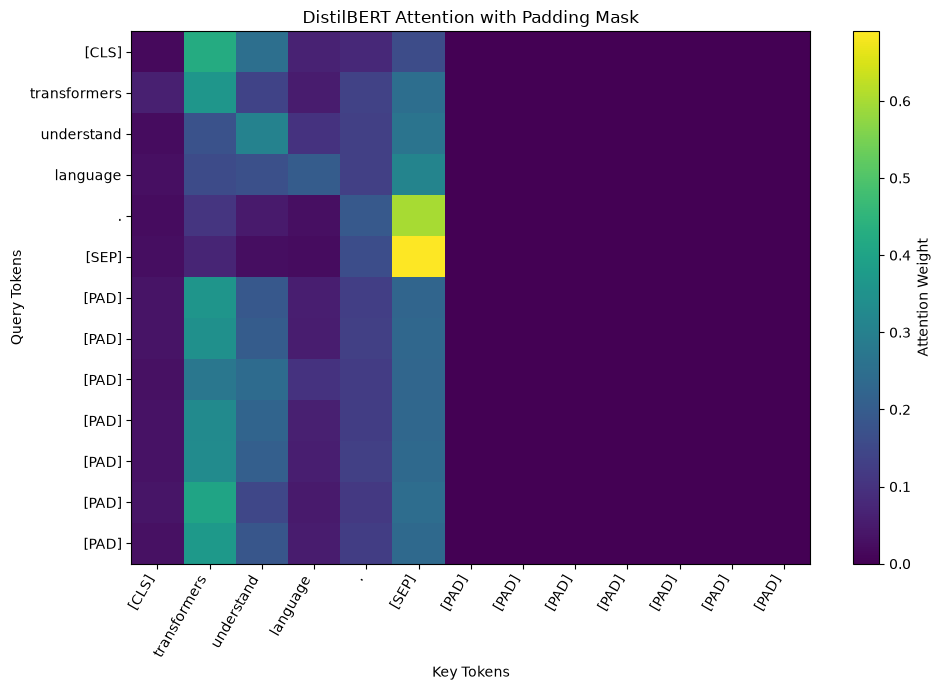

In [51]:
# Select the first sentence, which should contain padding
sentence_index = 0

attention_matrix = (
    last_attention[sentence_index]
    .mean(dim=0)
    .cpu()
    .numpy()
)

token_ids = batch_inputs["input_ids"][sentence_index].cpu().tolist()
tokens = tok.convert_ids_to_tokens(token_ids)

plt.figure(figsize=(10, 7))

plt.imshow(attention_matrix, cmap="viridis", aspect="auto")
plt.colorbar(label="Attention Weight")

plt.xticks(range(len(tokens)), tokens, rotation=60, ha="right")
plt.yticks(range(len(tokens)), tokens)

plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.title("DistilBERT Attention with Padding Mask")

plt.tight_layout()
plt.show()

### Padding Mask vs Causal Mask

| Feature | Padding Mask | Causal Mask |
|---|---|---|
| Purpose | Prevents attention to padding tokens | Prevents attention to future tokens |
| Pattern | Masks positions marked as padding | Masks positions above the main diagonal |
| Typical use | BERT, DistilBERT and GPT-2 with padded batches | Autoregressive models such as GPT-2 |
| Main benefit | Avoids attending to artificial padding tokens | Prevents future-token information from leaking into predictions |

### Observation

The padding mask prevents valid tokens from assigning attention
to padding key positions. The causal mask instead prevents tokens
from attending to future positions. Both control which token
relationships are allowed during attention, but they serve different
purposes.

# Task 5: Cross-Attention, Decoder Architecture & Inference


## Task 5.1: Decoder Architecture

### Original Transformer Decoder Block

The original Transformer decoder contains the following components:

1. Masked multi-head self-attention.
2. Residual connection followed by Layer Normalization.
3. Cross-attention over the encoder output.
4. Residual connection followed by Layer Normalization.
5. Position-wise feed-forward network.
6. Residual connection followed by Layer Normalization.
7. A final linear layer and softmax over the vocabulary to predict output tokens.

### Three Transformer Model Families

#### 1. Encoder-only: DistilBERT / BERT
Encoder-only models use bidirectional self-attention to build contextual
representations. They are useful for tasks such as sentiment analysis
and masked-word prediction.

#### 2. Decoder-only: GPT-2
Decoder-only models use causal self-attention so each token can attend
only to current and previous tokens. GPT-2 does not use encoder-decoder
cross-attention and is commonly used for text generation.

#### 3. Encoder-decoder: T5
Encoder-decoder models contain both an encoder and a decoder. The encoder
processes the input text, while the decoder uses masked self-attention
and cross-attention to generate the target text.

## Task 5.2: Cross-Attention

### What Is Cross-Attention?

In cross-attention, the Queries (Q) come from the decoder's current
representations, while the Keys (K) and Values (V) come from the
encoder output.

The decoder uses its queries to find relevant information in the
encoder's representations of the input sentence.

### How It Works

1. The encoder processes the source sentence and produces contextual
   representations.
2. The decoder processes the target sequence using masked self-attention.
3. The decoder creates Queries from its current hidden representations.
4. Keys and Values are derived from the encoder output.
5. Attention scores determine which source tokens are most relevant
   to each decoder position.
6. The weighted encoder information helps the decoder generate the
   target sequence.

### Relationship to Luong Attention

Luong attention also uses a decoder state to attend to encoder
representations. Cross-attention in Transformer models follows the
same broad idea, but uses learned projections and multi-head attention
rather than relying only on a single dot-product attention pattern.

## Task 5.3 — T5 Translation and Summarization

In [52]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

# Load T5-small directly
model_name = "t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(model_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

t5_model.eval()

sentences = [
    "The house is small.",
    "I love learning about artificial intelligence.",
    "The weather is beautiful today."
]

for sentence in sentences:
    # T5 translation instruction
    prompt = "translate English to French: " + sentence

    inputs = t5_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True
    )

    with torch.no_grad():
        output_ids = t5_model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    french_text = t5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    print("English:", sentence)
    print("French:", french_text)
    print("-" * 50)

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 572.60it/s]


English: The house is small.
French: La maison est petite.
--------------------------------------------------
English: I love learning about artificial intelligence.
French: Je m'aime apprendre sur l'intelligence artificielle.
--------------------------------------------------
English: The weather is beautiful today.
French: Le temps est beau aujourd'hui.
--------------------------------------------------


In [53]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

# Reuse t5_model and t5_tokenizer if already loaded
# Otherwise, load them:
try:
    t5_model
    t5_tokenizer
except NameError:
    t5_model_name = "t5-small"
    t5_tokenizer = AutoTokenizer.from_pretrained(t5_model_name)
    t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_model_name)

t5_model.eval()

paragraph = """
Artificial intelligence is increasingly being used in education,
healthcare, transportation, and business. In education, AI tools can
help students understand difficult topics and provide personalized
practice. In healthcare, machine learning systems can assist with
medical image analysis, although their outputs require validation.
Transportation systems use AI for route planning and traffic prediction.
Businesses use AI to analyze customer feedback and automate repetitive
tasks. However, these technologies introduce challenges. Models may
produce incorrect information, reflect biases in their training data,
or expose sensitive information if deployed carelessly. Organizations
should evaluate accuracy, protect privacy, and maintain human oversight.
AI systems are most useful when their limitations are understood and
their outputs are checked in situations where errors could cause harm.
"""

input_words = len(paragraph.split())

# T5 summarization instruction
prompt = "summarize: " + paragraph

inputs = t5_tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
)

with torch.no_grad():
    summary_ids = t5_model.generate(
        **inputs,
        max_length=60,
        min_length=20,
        do_sample=False
    )

summary = t5_tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

summary_words = len(summary.split())

print("Original paragraph:\n", paragraph)
print("\nSummary:\n", summary)
print("\nInput length:", input_words, "words")
print("Summary length:", summary_words, "words")

Original paragraph:
 
Artificial intelligence is increasingly being used in education,
healthcare, transportation, and business. In education, AI tools can
help students understand difficult topics and provide personalized
practice. In healthcare, machine learning systems can assist with
medical image analysis, although their outputs require validation.
Transportation systems use AI for route planning and traffic prediction.
Businesses use AI to analyze customer feedback and automate repetitive
tasks. However, these technologies introduce challenges. Models may
produce incorrect information, reflect biases in their training data,
or expose sensitive information if deployed carelessly. Organizations
should evaluate accuracy, protect privacy, and maintain human oversight.
AI systems are most useful when their limitations are understood and
their outputs are checked in situations where errors could cause harm.


Summary:
 technology is increasingly being used in education, healthcare, tra

## Task 5.4 — Extract and Plot Cross-Attention

In [54]:
from transformers import AutoTokenizer, T5ForConditionalGeneration
import torch

model_name = "t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(model_name)

t5_model = T5ForConditionalGeneration.from_pretrained(
    model_name,
    attn_implementation="eager"
)

t5_model.eval()

print("Model loaded with eager attention.")

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 490.08it/s]

Model loaded with eager attention.


In [55]:
import numpy as np
import matplotlib.pyplot as plt

source_text = "translate English to French: The house is small."
target_text = "La maison est petite."

encoder_inputs = t5_tokenizer(
    source_text,
    return_tensors="pt"
)

target_inputs = t5_tokenizer(
    target_text,
    return_tensors="pt"
)

labels = target_inputs["input_ids"].clone()
labels[labels == t5_tokenizer.pad_token_id] = -100

with torch.no_grad():
    outputs = t5_model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        labels=labels,
        output_attentions=True
    )

print("Number of decoder cross-attention layers:",
      len(outputs.cross_attentions))

if len(outputs.cross_attentions) == 0:
    raise RuntimeError(
        "Cross-attention is empty. Confirm that the model was reloaded "
        "with attn_implementation='eager'."
    )

# Last decoder layer, first example, average across heads
cross_attention = (
    outputs.cross_attentions[-1][0]
    .mean(dim=0)
    .cpu()
    .numpy()
)

input_tokens = t5_tokenizer.convert_ids_to_tokens(
    encoder_inputs["input_ids"][0].tolist()
)

output_tokens = t5_tokenizer.convert_ids_to_tokens(
    target_inputs["input_ids"][0].tolist()
)

print("Cross-attention shape:", cross_attention.shape)
print("Input tokens:", input_tokens)
print("Output tokens:", output_tokens)

Number of decoder cross-attention layers: 6
Cross-attention shape: (6, 11)
Input tokens: ['▁translate', '▁English', '▁to', '▁French', ':', '▁The', '▁house', '▁is', '▁small', '.', '</s>']
Output tokens: ['▁La', '▁maison', '▁est', '▁petite', '.', '</s>']


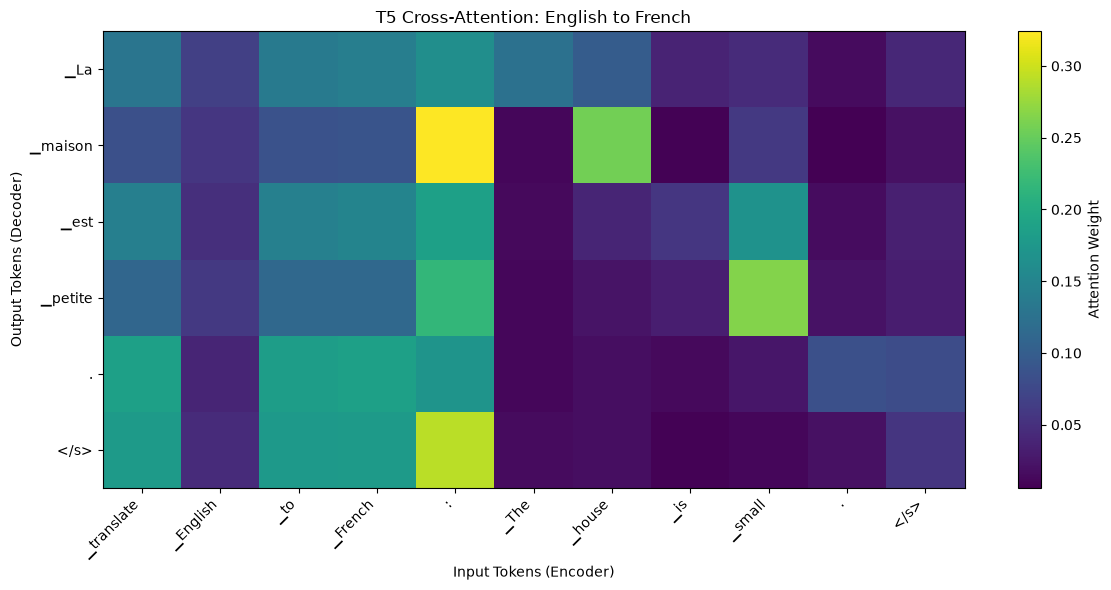

In [56]:
plt.figure(figsize=(12, 6))

plt.imshow(cross_attention, cmap="viridis", aspect="auto")
plt.colorbar(label="Attention Weight")

plt.xticks(
    range(len(input_tokens)),
    input_tokens,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(output_tokens)), output_tokens)

plt.xlabel("Input Tokens (Encoder)")
plt.ylabel("Output Tokens (Decoder)")
plt.title("T5 Cross-Attention: English to French")

plt.tight_layout()
plt.savefig("t5_cross_attention.png")
plt.show()

## Task 5.5 — Manual Greedy Decoding with GPT-2

In [57]:
import torch

# Prompt specified in PR 6
prompt = "Artificial intelligence will"

gpt2_model.eval()

# Tokenize the prompt
inputs = gpt2_tokenizer(
    prompt,
    return_tensors="pt"
)

device = next(gpt2_model.parameters()).device
input_ids = inputs["input_ids"].to(device)

# Start with the prompt tokens
generated_ids = input_ids.clone()

# Manual greedy decoding: generate 20 new tokens
with torch.no_grad():
    for step in range(20):
        outputs = gpt2_model(input_ids=generated_ids)

        # Get logits for the next token
        next_token_logits = outputs.logits[:, -1, :]

        # Select the token with the highest score
        next_token = torch.argmax(
            next_token_logits,
            dim=-1,
            keepdim=True
        )

        # Append the selected token
        generated_ids = torch.cat(
            [generated_ids, next_token],
            dim=1
        )

manual_text = gpt2_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("Manual greedy decoding:\n")
print(manual_text)

print("\nGenerated new tokens:", generated_ids.shape[1] - input_ids.shape[1])

Manual greedy decoding:

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Generated new tokens: 20


In [58]:
with torch.no_grad():
    generated_by_model = gpt2_model.generate(
        input_ids=input_ids,
        max_new_tokens=20,
        do_sample=False
    )

generate_text = gpt2_tokenizer.decode(
    generated_by_model[0],
    skip_special_tokens=True
)

print("Manual output:\n", manual_text)
print("\nmodel.generate() output:\n", generate_text)

# Compare token IDs, including the original prompt
identical = torch.equal(
    generated_ids,
    generated_by_model
)

print("\nAre both token sequences identical?", identical)

Manual output:
 Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

model.generate() output:
 Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Are both token sequences identical? True


## Task 5.6 — Compare Five Decoding Strategies

In [59]:
import torch
import pandas as pd
from transformers import set_seed

prompt = "Artificial intelligence will"

inputs = gpt2_tokenizer(
    prompt,
    return_tensors="pt"
)

device = next(gpt2_model.parameters()).device
input_ids = inputs["input_ids"].to(device)

gpt2_model.eval()

def generate_text(seed, **generation_kwargs):
    set_seed(seed)

    with torch.no_grad():
        output_ids = gpt2_model.generate(
            input_ids=input_ids,
            max_new_tokens=40,
            pad_token_id=gpt2_tokenizer.eos_token_id,
            **generation_kwargs
        )

    return gpt2_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )


results = []

# 1. Greedy decoding
results.append({
    "Strategy": "Greedy",
    "Run": 1,
    "Output": generate_text(
        42,
        do_sample=False,
        num_beams=1
    )
})

# 2. Beam search
results.append({
    "Strategy": "Beam Search (5 beams)",
    "Run": 1,
    "Output": generate_text(
        42,
        do_sample=False,
        num_beams=5,
        early_stopping=True
    )
})

# 3. Temperature 0.7 — two different seeds
for run, seed in enumerate([42, 123], start=1):
    results.append({
        "Strategy": "Sampling (T=0.7)",
        "Run": run,
        "Output": generate_text(
            seed,
            do_sample=True,
            temperature=0.7
        )
    })

# 4. Temperature 1.5 — two different seeds
for run, seed in enumerate([42, 123], start=1):
    results.append({
        "Strategy": "Sampling (T=1.5)",
        "Run": run,
        "Output": generate_text(
            seed,
            do_sample=True,
            temperature=1.5
        )
    })

# 5. Top-k + top-p sampling
results.append({
    "Strategy": "Top-k=50 + Top-p=0.9",
    "Run": 1,
    "Output": generate_text(
        42,
        do_sample=True,
        top_k=50,
        top_p=0.9,
        temperature=1.0
    )
})

results_df = pd.DataFrame(results)

with pd.option_context(
    "display.max_colwidth", 500,
    "display.max_rows", None
):
    display(results_df)

,Strategy,Run,Output
0,Greedy,1,"Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.\n\n""We're going to be able to"
1,Beam Search (5 beams),1,"Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.\n\n""I think it's going to take a lot of work to get there,"" he said"
2,Sampling (T=0.7),1,"Artificial intelligence will be used to create artificial intelligence in the future, but it is not yet a fully mature technology. For example, there is no commercial use of artificial intelligence in the United States. The United States is"
3,Sampling (T=0.7),2,"Artificial intelligence will not only reduce the speed of our daily lives, but also the way we think and behave. This enables us to adapt our lives to change our thinking, so that we will be able to think with"
4,Sampling (T=1.5),1,"Artificial intelligence will continue to expand a billion ways in just the near future, experts warn, and new tech could help it. The technology is the most widely studied because it looks what you'd describe as a completely separate"
5,Sampling (T=1.5),2,"Artificial intelligence will not only reduce the speed of its process by up to 70%, but by at least 20%. This enables us to provide more targeted targeting towards our patients through this technique rather than targeting that much too late"
6,Top-k=50 + Top-p=0.9,1,"Artificial intelligence will continue to expand to create new types of AI, but it is still hard to see how we can make an AI that is completely compatible with artificial intelligence. In fact, even if we made an AI"


## Task 5.7 — KV-Cache Speed-Up

In [60]:
import time
import torch
import numpy as np

prompt = "Artificial intelligence will"

inputs = gpt2_tokenizer(
    prompt,
    return_tensors="pt"
)

device = next(gpt2_model.parameters()).device
input_ids = inputs["input_ids"].to(device)

gpt2_model.eval()

def time_generation(use_cache, runs=3):
    times = []

    for run in range(runs):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        with torch.no_grad():
            output = gpt2_model.generate(
                input_ids=input_ids,
                max_new_tokens=100,
                do_sample=False,
                use_cache=use_cache,
                pad_token_id=gpt2_tokenizer.eos_token_id
            )

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start_time
        times.append(elapsed)

        print(
            f"use_cache={use_cache}, "
            f"run {run + 1}: {elapsed:.3f} seconds"
        )

    return times


print("Running with KV cache enabled...")
times_cache = time_generation(use_cache=True, runs=3)

print("\nRunning with KV cache disabled...")
times_no_cache = time_generation(use_cache=False, runs=3)

avg_cache = np.mean(times_cache)
avg_no_cache = np.mean(times_no_cache)

print("\n--- Average Results ---")
print(f"Average with cache:    {avg_cache:.3f} seconds")
print(f"Average without cache: {avg_no_cache:.3f} seconds")

if avg_cache > 0:
    speedup = avg_no_cache / avg_cache
    print(f"Speed-up ratio: {speedup:.2f}x")

Running with KV cache enabled...
use_cache=True, run 1: 2.654 seconds
use_cache=True, run 2: 2.524 seconds
use_cache=True, run 3: 2.234 seconds

Running with KV cache disabled...
use_cache=False, run 1: 5.411 seconds
use_cache=False, run 2: 6.426 seconds
use_cache=False, run 3: 5.941 seconds

--- Average Results ---
Average with cache:    2.470 seconds
Average without cache: 5.926 seconds
Speed-up ratio: 2.40x


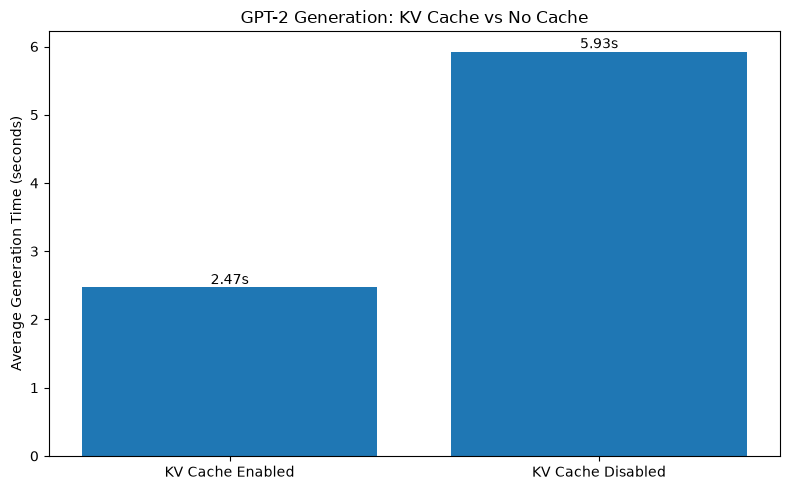

In [61]:
import matplotlib.pyplot as plt

labels = ["KV Cache Enabled", "KV Cache Disabled"]
average_times = [avg_cache, avg_no_cache]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, average_times)

plt.ylabel("Average Generation Time (seconds)")
plt.title("GPT-2 Generation: KV Cache vs No Cache")

for bar, value in zip(bars, average_times):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("kv_vs_no_cache.png")
plt.show()

## Task 5.8: Inference Summary — Model Family Comparison

### Objective
Compare DistilBERT, GPT-2, and T5-small in terms of architecture,
attention mechanisms, text generation, positional encoding, and typical tasks.

### Model Family Comparison

| Feature | DistilBERT | GPT-2 | T5-small |
|---|---|---|---|
| Model family | Encoder-only | Decoder-only | Encoder-decoder |
| Attention types | Bidirectional self-attention | Causal masked self-attention | Encoder self-attention, decoder causal self-attention, and cross-attention |
| Can generate text? | Not designed for autoregressive generation | Yes | Yes |
| Position scheme | Learned absolute positional embeddings | Learned absolute positional embeddings | Relative position biases |
| Typical tasks | Sentiment analysis, fill-mask | Text generation, next-token prediction | Translation, summarization, text-to-text tasks |
| Example in this notebook | Sentiment pipeline and attention heatmap | Manual greedy decoding and KV-cache timing | Translation attempt and cross-attention heatmap |

### Observation

The three models represent different Transformer architectures.
DistilBERT builds contextual representations using bidirectional attention,
GPT-2 generates text autoregressively using causal attention, and T5
uses an encoder and decoder connected by cross-attention.

The architecture and training objective determine which tasks each
model is best suited for. The quality of generated outputs also depends
on the specific pretrained checkpoint and its training.

# Task 6: Mini Application, Evaluation & Disadvantages in Practice


In [62]:
import sys
import datasets
import huggingface_hub

print("Python:", sys.executable)
print("Datasets:", datasets.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

Python: c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\PR 6\.venv\Scripts\python.exe
Datasets: 5.1.0
Hugging Face Hub: 2.3.0


In [63]:
from datasets import load_dataset

imdb_dataset = load_dataset(
    "stanfordnlp/imdb",
    split="test"
)

print("Total reviews:", len(imdb_dataset))

Total reviews: 25000


In [64]:
# Select a reproducible sample of 200 reviews
imdb_sample = imdb_dataset.shuffle(seed=42).select(range(200))

texts = imdb_sample["text"]
true_labels = imdb_sample["label"]

print("Sample size:", len(texts))
print("First review:", texts[0][:300])
print("First label:", true_labels[0])

Sample size: 200
First review: <br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I sta
First label: 1


In [65]:
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

sentiment_tokenizer = AutoTokenizer.from_pretrained(model_name)
sentiment_model = AutoModelForSequenceClassification.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sentiment_model.to(device)
sentiment_model.eval()

print("Device:", device)
print("Model loaded successfully!")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 742.25it/s]

Device: cpu
Model loaded successfully!


In [66]:
predicted_labels = []
prediction_scores = []
batch_size = 16

for start in range(0, len(texts), batch_size):
    batch_texts = texts[start:start + batch_size]

    encoded = sentiment_tokenizer(
        batch_texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        outputs = sentiment_model(**encoded)
        probabilities = torch.softmax(outputs.logits, dim=-1)

    batch_predictions = torch.argmax(
        probabilities, dim=-1
    ).cpu().tolist()

    batch_scores = probabilities.max(
        dim=-1
    ).values.cpu().tolist()

    predicted_labels.extend(batch_predictions)
    prediction_scores.extend(batch_scores)

print("Predictions completed:", len(predicted_labels))

Predictions completed: 200


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_true = np.array(true_labels)
y_pred = np.array(predicted_labels)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

Accuracy : 0.8400
Precision: 0.8636
Recall   : 0.7917
F1 Score : 0.8261

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.88      0.85       104
    Positive       0.86      0.79      0.83        96

    accuracy                           0.84       200
   macro avg       0.84      0.84      0.84       200
weighted avg       0.84      0.84      0.84       200



In [68]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


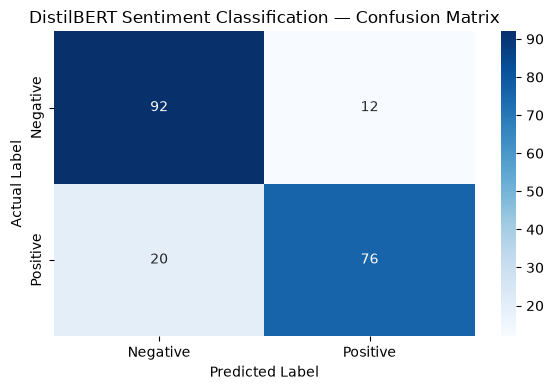

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT Sentiment Classification — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Task 6.2 — Truncation Study

In [70]:
import time
import numpy as np
import pandas as pd
import torch

# Count tokens in each review before truncation
original_lengths = []

for text in texts:
    token_ids = sentiment_tokenizer(
        text,
        truncation=False,
        add_special_tokens=True
    )["input_ids"]

    original_lengths.append(len(token_ids))

print("Total reviews:", len(original_lengths))
print("Reviews longer than 512 tokens:", sum(
    length > 512 for length in original_lengths
))
print("Longest review:", max(original_lengths), "tokens")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Total reviews: 200
Reviews longer than 512 tokens: 18
Longest review: 1453 tokens


In [71]:
max_lengths = [64, 128, 256, 512]
results = []

y_true = np.array(true_labels)

for max_len in max_lengths:
    predictions = []
    start_time = time.perf_counter()

    batch_size = 16

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = sentiment_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_len,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():
            outputs = sentiment_model(**encoded)
            batch_predictions = torch.argmax(
                outputs.logits, dim=-1
            ).cpu().tolist()

        predictions.extend(batch_predictions)

    # Ensure GPU operations finish before stopping the timer
    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_time = time.perf_counter() - start_time

    from sklearn.metrics import accuracy_score, f1_score

    accuracy = accuracy_score(y_true, predictions)
    f1 = f1_score(y_true, predictions, zero_division=0)

    results.append({
        "Max Tokens": max_len,
        "Accuracy": accuracy,
        "F1 Score": f1,
        "Time (seconds)": elapsed_time
    })

    print(
        f"Max length: {max_len} | "
        f"Accuracy: {accuracy:.4f} | "
        f"F1: {f1:.4f} | "
        f"Time: {elapsed_time:.2f}s"
    )

truncation_df = pd.DataFrame(results)
truncation_df

Max length: 64 | Accuracy: 0.7500 | F1: 0.7253 | Time: 4.09s
Max length: 128 | Accuracy: 0.7750 | F1: 0.7692 | Time: 7.31s
Max length: 256 | Accuracy: 0.8400 | F1: 0.8261 | Time: 14.79s
Max length: 512 | Accuracy: 0.8700 | F1: 0.8602 | Time: 31.26s


,Max Tokens,Accuracy,F1 Score,Time (seconds)
0,64,0.750,0.725275,4.087955
1,128,0.775,0.769231,7.314333
2,256,0.840,0.826087,14.792354
3,512,0.870,0.860215,31.257110


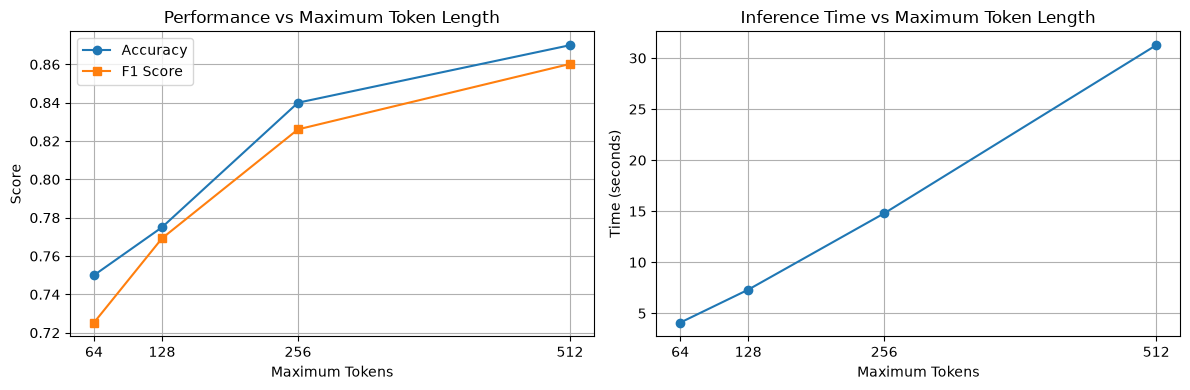

In [72]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    truncation_df["Max Tokens"],
    truncation_df["Accuracy"],
    marker="o",
    label="Accuracy"
)
axes[0].plot(
    truncation_df["Max Tokens"],
    truncation_df["F1 Score"],
    marker="s",
    label="F1 Score"
)
axes[0].set_title("Performance vs Maximum Token Length")
axes[0].set_xlabel("Maximum Tokens")
axes[0].set_ylabel("Score")
axes[0].set_xticks([64, 128, 256, 512])
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    truncation_df["Max Tokens"],
    truncation_df["Time (seconds)"],
    marker="o"
)
axes[1].set_title("Inference Time vs Maximum Token Length")
axes[1].set_xlabel("Maximum Tokens")
axes[1].set_ylabel("Time (seconds)")
axes[1].set_xticks([64, 128, 256, 512])
axes[1].grid(True)

plt.tight_layout()
plt.savefig("perfomance_timevs_maxtokenlentght.png")
plt.show()

## Task 6.3 — Forward-Pass Time vs Input Length

In [73]:
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Sequence lengths to benchmark
sequence_lengths = [32, 64, 128, 256, 512]

# Use the same review for a controlled comparison
sample_text = texts[0]

benchmark_results = []

sentiment_model.eval()

for seq_len in sequence_lengths:

    # Tokenize and create an input of the exact required length
    encoded = sentiment_tokenizer(
        sample_text,
        max_length=seq_len,
        truncation=True,
        padding="max_length",
        return_tensors="pt"
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    # Warm-up: initialize model execution before timing
    with torch.no_grad():
        for _ in range(3):
            _ = sentiment_model(**encoded)

    if device.type == "cuda":
        torch.cuda.synchronize()

    # Measure repeated forward passes
    repetitions = 20
    start_time = time.perf_counter()

    with torch.no_grad():
        for _ in range(repetitions):
            _ = sentiment_model(**encoded)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time
    avg_time_ms = (elapsed / repetitions) * 1000

    benchmark_results.append({
        "Sequence Length": seq_len,
        "Average Forward-Pass Time (ms)": avg_time_ms
    })

    print(
        f"Length: {seq_len:3d} tokens | "
        f"Average time: {avg_time_ms:.3f} ms"
    )

benchmark_df = pd.DataFrame(benchmark_results)
benchmark_df

Length:  32 tokens | Average time: 17.755 ms
Length:  64 tokens | Average time: 27.767 ms
Length: 128 tokens | Average time: 50.081 ms
Length: 256 tokens | Average time: 83.584 ms
Length: 512 tokens | Average time: 178.162 ms


,Sequence Length,Average Forward-Pass Time (ms)
0,32,17.755145
1,64,27.766540
2,128,50.081050
3,256,83.584270
4,512,178.162500


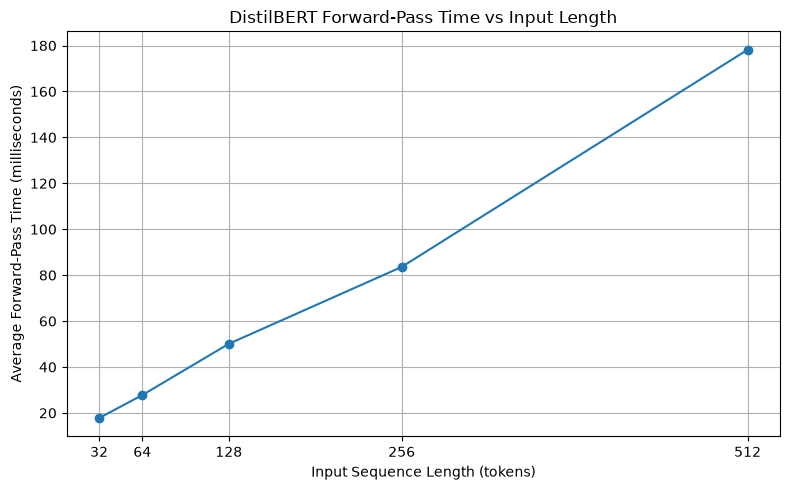

In [74]:
plt.figure(figsize=(8, 5))

plt.plot(
    benchmark_df["Sequence Length"],
    benchmark_df["Average Forward-Pass Time (ms)"],
    marker="o"
)

plt.title("DistilBERT Forward-Pass Time vs Input Length")
plt.xlabel("Input Sequence Length (tokens)")
plt.ylabel("Average Forward-Pass Time (milliseconds)")
plt.xticks(sequence_lengths)
plt.grid(True)
plt.tight_layout()
plt.show()

## Task 6.4 — GPT-2 Hallucination Check

In [75]:
print("Model loaded:", gpt2_model is not None)
print("Tokenizer loaded:", gpt2_tokenizer is not None)

gpt2_model.eval()

Model loaded: True
Tokenizer loaded: True


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [76]:
prompts = [
    "The capital city of Australia is",
    "Pride and Prejudice was written by",
    "The telephone is commonly credited to"
]

hallucination_results = []

for prompt in prompts:
    inputs = gpt2_tokenizer(
        prompt,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        output_ids = gpt2_model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )

    generated_text = gpt2_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    hallucination_results.append({
        "Prompt": prompt,
        "Generated Response": generated_text
    })

    print("=" * 70)
    print("PROMPT:", prompt)
    print("GENERATED:", generated_text)

PROMPT: The capital city of Australia is
GENERATED: The capital city of Australia is home to the world's largest population of people, and the largest number of people living in the country.

The city is home to the world
PROMPT: Pride and Prejudice was written by
GENERATED: Pride and Prejudice was written by the author of the book, and is available for purchase from Amazon.com.

The book is available for purchase from Amazon.com.

PROMPT: The telephone is commonly credited to
GENERATED: The telephone is commonly credited to the late Dr. William H. H. Haldeman, who was a physician and physician-in-chief of the University of Chicago Medical School


In [77]:
import pandas as pd

hallucination_df = pd.DataFrame(hallucination_results)
hallucination_df

,Prompt,Generated Response
0,The capital city of Australia is,The capital city of Australia is home to the w...
1,Pride and Prejudice was written by,Pride and Prejudice was written by the author ...
2,The telephone is commonly credited to,The telephone is commonly credited to the late...


## Task 6.5 — Build text_toolkit(text)

In [78]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

t5_name = "t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(t5_name)

t5_model = AutoModelForSeq2SeqLM.from_pretrained(
    t5_name,
    attn_implementation="eager"
)

t5_model.to(device)
t5_model.eval()

print("T5-small loaded successfully!")

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 592.52it/s]

T5-small loaded successfully!


In [79]:
def text_toolkit(text):
    """
    Perform sentiment analysis, summarization,
    and English-to-French translation.

    Returns a dictionary containing:
    sentiment, sentiment_score, summary, and french_translation.
    """

    # Handle invalid or empty input
    if not isinstance(text, str) or not text.strip():
        return {
            "sentiment": "N/A",
            "sentiment_score": 0.0,
            "summary": "No text provided.",
            "french_translation": "Aucun texte fourni."
        }

    # Limit input length for both models
    cleaned_text = text.strip()

    # --------------------------------
    # 1. Sentiment Analysis
    # --------------------------------
    sentiment_inputs = sentiment_tokenizer(
        cleaned_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    sentiment_inputs = {
        key: value.to(device)
        for key, value in sentiment_inputs.items()
    }

    with torch.no_grad():
        sentiment_outputs = sentiment_model(**sentiment_inputs)
        sentiment_probs = torch.softmax(
            sentiment_outputs.logits,
            dim=-1
        )[0]

    sentiment_id = int(torch.argmax(sentiment_probs).item())
    sentiment_score = float(sentiment_probs[sentiment_id].item())

    sentiment = sentiment_model.config.id2label[sentiment_id]

    # --------------------------------
    # 2. Text Summarization
    # --------------------------------
    summary_prompt = "summarize: " + cleaned_text

    summary_inputs = t5_tokenizer(
        summary_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    summary_inputs = {
        key: value.to(device)
        for key, value in summary_inputs.items()
    }

    with torch.no_grad():
        summary_ids = t5_model.generate(
            **summary_inputs,
            max_new_tokens=60,
            num_beams=4,
            do_sample=False
        )

    summary = t5_tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    ).strip()

    # --------------------------------
    # 3. English-to-French Translation
    # --------------------------------
    if summary:
        translation_prompt = (
            "translate English to French: " + summary
        )

        translation_inputs = t5_tokenizer(
            translation_prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        )

        translation_inputs = {
            key: value.to(device)
            for key, value in translation_inputs.items()
        }

        with torch.no_grad():
            translation_ids = t5_model.generate(
                **translation_inputs,
                max_new_tokens=60,
                num_beams=4,
                do_sample=False
            )

        french_translation = t5_tokenizer.decode(
            translation_ids[0],
            skip_special_tokens=True
        ).strip()
    else:
        french_translation = ""

    # Return all results
    return {
        "sentiment": sentiment,
        "sentiment_score": round(sentiment_score, 4),
        "summary": summary,
        "french_translation": french_translation
    }


print("text_toolkit() function defined successfully!")

text_toolkit() function defined successfully!


In [80]:
passages = [
    # 1. Product/movie review
    """
    The movie has excellent acting, beautiful cinematography,
    and a powerful story. The pacing is slightly slow in the
    middle, but the ending is emotional and satisfying.
    """,

    # 2. News-style passage
    """
    A city government announced a new public transport plan.
    The plan includes additional electric buses, improved
    bus stops, and digital ticketing. Officials said the
    changes are intended to reduce traffic congestion and
    improve public transport accessibility.
    """,

    # 3. Own passage
    """
    Artificial intelligence is changing how students learn.
    AI tools can explain difficult concepts, help with coding,
    and provide practice questions. However, students should
    verify important information and develop their own
    problem-solving skills instead of copying every answer.
    """
]

toolkit_results = []

for i, passage in enumerate(passages, start=1):
    result = text_toolkit(passage)

    toolkit_results.append({
        "Passage": f"Passage {i}",
        "Original Text": passage.strip(),
        "Sentiment": result["sentiment"],
        "Sentiment Score": result["sentiment_score"],
        "Summary": result["summary"],
        "French Translation": result["french_translation"]
    })

    print(f"Passage {i} completed.")

print("All three passages processed!")

Passage 1 completed.
Passage 2 completed.
Passage 3 completed.
All three passages processed!


In [81]:
import pandas as pd

toolkit_df = pd.DataFrame(toolkit_results)

pd.set_option("display.max_colwidth", 250)

display(toolkit_df)

,Passage,Original Text,Sentiment,Sentiment Score,Summary,French Translation
0,Passage 1,"The movie has excellent acting, beautiful cinematography,\n and a powerful story. The pacing is slightly slow in the\n middle, but the ending is emotional and satisfying.",POSITIVE,0.9999,"the pacing is slightly slow in the middle, but the ending is emotional and satisfying.","le pacing est légèrement lent au milieu, mais la fin est émotionnelle et satisfaisante."
1,Passage 2,"A city government announced a new public transport plan.\n The plan includes additional electric buses, improved\n bus stops, and digital ticketing. Officials said the\n changes are intended to reduce traffic congestion and\n improve ...",NEGATIVE,0.6709,"new public transport plan includes electric buses, improved bus stops and digital ticketing. the changes are intended to reduce traffic congestion and improve public transport accessibility.","Le nouveau plan de transport en commun comprend les autobus électriques, l'amélioration des arrêts d'autobus et la délivrance de billets numériques."
2,Passage 3,"Artificial intelligence is changing how students learn.\n AI tools can explain difficult concepts, help with coding,\n and provide practice questions. However, students should\n verify important information and develop their own\n pro...",POSITIVE,0.9807,"AI tools can explain difficult concepts, help with coding, and provide practice questions. students should verify important information and develop their own problem-solving skills instead of copying every answer.","Les outils d'AI peuvent expliquer les concepts difficiles, aider au codage et poser des questions pratiques. Les élèves devraient vérifier l'information importante et développer leurs propres compétences en matière de résolution de problèmes plut..."


In [82]:
empty_result = text_toolkit("")

print(empty_result)

{'sentiment': 'N/A', 'sentiment_score': 0.0, 'summary': 'No text provided.', 'french_translation': 'Aucun texte fourni.'}


## Task 6.6 — What I Learned About Transformers

Through this practical, I learned how Transformer models process text using tokenization, embeddings, self-attention, and positional encoding. I understood that attention helps a model identify relationships between different words in a sequence.

I explored the differences between encoder-only, decoder-only, and encoder-decoder architectures. DistilBERT uses bidirectional attention and is useful for sentiment classification, while GPT-2 uses causal attention to generate text one token at a time. T5 uses an encoder-decoder architecture for text-to-text tasks such as summarization and translation.

I also learned how padding masks and causal masks control which tokens a model can attend to. Multi-head attention allows the model to learn different types of relationships between words, while Layer Normalization helps stabilize the network.

During the practical experiments, I evaluated a pretrained sentiment model using accuracy, precision, recall, F1 score, and a confusion matrix. I investigated how input length affects inference time and model performance. I also tested GPT-2 with factual prompts and learned that fluent generated text is not always factually correct.

Finally, I combined sentiment analysis, summarization, and French translation into a single text toolkit using pretrained models. This practical helped me understand the architecture, capabilities, and limitations of Transformer models in real-world NLP applications.

Overall, I learned that Transformer models are powerful tools for language processing, but their outputs should be evaluated carefully, especially when factual accuracy is important.

In [83]:

pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
